# Echo Class 函数使用示例

插件类：
- SteinerConvStratPlugin
- FeatureDetectionPlugin
- HydroclassSemisupervisedPlugin
- ConvStratRautPlugin

## 1. 导入依赖

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, Normalize
import meteva_base as meb
import numpy as np
import pyart

# 设置中文图题和负号显示。
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "SimSun", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

NOTEBOOK_DIR = Path.cwd()  # notebook目录 radar_echo_classification/nbs
ECHO_CLASS_DIR = NOTEBOOK_DIR.parent  # echo_class/
REPO_ROOT = ECHO_CLASS_DIR.parent  # 项目根目录
TEST_DATA_DIR = ECHO_CLASS_DIR / 'test_data' / 'echo_class'  #测试数据目录
CLI_INPUT = TEST_DATA_DIR / 'cli_input'  # cli示例输入数据目录
CLI_OUTPUT = TEST_DATA_DIR / 'cli_output'  # cli示例输出数据目录
CLI_INPUT.mkdir(parents=True, exist_ok=True)
CLI_OUTPUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO_ROOT))

# 修改后算法导入
from radar_echo_classification.src.echo_class import (
    ConvStratRautPlugin,
    FeatureDetectionPlugin,
    HydroclassSemisupervisedPlugin,
    SteinerConvStratPlugin,
)


d:\workspace\pyart_nimm\venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources



## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly
## supported by the U.S. Department of Energy as part of the Atmospheric
## Radiation Measurement (ARM) Climate Research Facility, an Office of
## Science user facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



### 绘图函数定义

In [2]:
from cinrad_data import get_font_path
from matplotlib.font_manager import FontProperties
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable
from cinrad.visualize.utils import (
    cmap_cbar,
    cmap_plot,
    cbar_text,
    norm_cbar,
    norm_plot,
    prodname,
    unit,
)


def _colorbar_tick_positions(cbar_norm, labels, *, plot_norm=None):
    """计算色标刻度位置；分类场用 BoundaryNorm 类别中心。"""
    labels = list(labels)
    n = len(labels)
    if n == 0:
        return None, None

    boundary_norm = plot_norm if isinstance(plot_norm, BoundaryNorm) else None
    if boundary_norm is None and isinstance(cbar_norm, BoundaryNorm):
        boundary_norm = cbar_norm
    if boundary_norm is not None:
        bounds = np.asarray(boundary_norm.boundaries, dtype=float)
        if bounds.size >= n + 1:
            tick_pos = (bounds[:n] + bounds[1 : n + 1]) / 2.0
            return tick_pos, labels
        return np.arange(n, dtype=float), labels

    vmin = float(getattr(cbar_norm, "vmin", 0.0))
    vmax = float(getattr(cbar_norm, "vmax", 1.0))
    return np.linspace(vmin, vmax, n), labels


def plot_lonlat_field(
    data,
    lon,
    lat,
    field_name,
    title,
    *,
    extent=None,
    cmap=None,
    norm=None,
    cbar_label=None,
    cbar_tick_labels=None,
    figsize=(8.0, 6.5),
):
    """用 cinrad 内置 cmap/norm 在经纬度网格上填色绘图。"""
    # 获取中文字体
    my_font = FontProperties(fname=get_font_path())

    use_cinrad_cbar = cmap is None and norm is None and cbar_tick_labels is None
    if use_cinrad_cbar:
        dtype = str(field_name).strip().upper()
        if dtype not in norm_plot:
            raise ValueError(f"Unknown cinrad field: {field_name}")
        plot_cmap = cmap_plot[dtype]

        plot_norm = norm_plot[dtype]
        cbar_cmap = cmap_cbar[dtype]
        cbar_norm = norm_cbar[dtype]
        tick_labels = cbar_text.get(dtype)
    else:
        dtype = str(field_name).strip().upper()
        plot_cmap = cmap
        plot_norm = norm
        cbar_cmap = cmap
        cbar_norm = norm
        tick_labels = cbar_tick_labels

    values = np.asarray(data, dtype=np.float32)
    lon = np.asarray(lon, dtype=np.float64)
    lat = np.asarray(lat, dtype=np.float64)
    if lon.ndim == 1 and lat.ndim == 1:
        lon_plot, lat_plot = np.meshgrid(lon, lat)
    else:
        lon_plot, lat_plot = lon, lat

    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    ax.pcolormesh(lon_plot, lat_plot, values, cmap=plot_cmap, norm=plot_norm, shading="auto")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect("equal", adjustable="box")
    if extent is not None:
        ax.set_xlim(extent[0], extent[1])
        ax.set_ylim(extent[2], extent[3])
    ax.grid(True, linestyle="--", linewidth=0.6, color="0.45", alpha=0.55)

    cax = make_axes_locatable(ax).append_axes("right", size="3.5%", pad=0.12)
    cbar = ColorbarBase(
        cax,
        cmap=cbar_cmap,
        norm=cbar_norm,
        orientation="vertical",
    )
    cbar.ax.tick_params(axis="both", which="both", length=0, labelsize=9)

    # 对色标标签应用中文字体
    if cbar_label is not None:
        cbar.set_label(cbar_label, fontproperties=my_font)
    elif use_cinrad_cbar:
        unit_label = unit.get(dtype, "")
        name = prodname.get(dtype, dtype)
        cbar.set_label(f"{name} ({unit_label})" if unit_label else name, fontproperties=my_font)

    if tick_labels is not None:
        tick_pos, tick_lbl = _colorbar_tick_positions(
            cbar_norm,
            tick_labels,
            plot_norm=plot_norm if not use_cinrad_cbar else None,
        )
        if tick_pos is not None:
            cbar.set_ticks(tick_pos)
            cbar.set_ticklabels([str(t) for t in tick_lbl])
            # 对色标刻度标签应用中文字体
            for label in cbar.ax.get_yticklabels():
                label.set_fontproperties(my_font)

    # 对标题应用中文字体
    fig.suptitle(title, fontproperties=my_font)
    
    return type("LonLatPlot", (), {"fig": fig, "ax": ax, "cbar": cbar})()


def plot_categorical_comparison(
    name,
    left_data,
    right_data,
    extent=None,
    *,
    x_coords=None,
    y_coords=None,
    x_label="Longitude",
    y_label="Latitude",
    class_labels=None,
    left_title=None,
    right_title=None,
    diff_title=None,
):
    """对比两幅分类场及其差值（官方/迁移，或 CLI/官方 等）。"""
    # 获取中文字体
    my_font = FontProperties(fname=get_font_path())
    if left_data.shape != right_data.shape:
        raise ValueError(
            f"形状不匹配 对于 {name}: left={left_data.shape}, right={right_data.shape}"
        )

    valid = np.isfinite(left_data) & np.isfinite(right_data)
    diff_data = np.full_like(left_data, np.nan, dtype=np.float32)
    diff_data[valid] = left_data[valid] - right_data[valid]

    class_values = np.concatenate(
        [
            left_data[np.isfinite(left_data)],
            right_data[np.isfinite(right_data)],
        ]
    )
    if class_values.size:
        min_class = int(np.nanmin(class_values))
        max_class = int(np.nanmax(class_values))
    else:
        min_class, max_class = 0, 3
    boundaries = np.arange(min_class - 0.5, max_class + 1.5, 1.0)
    norm = BoundaryNorm(boundaries, ncolors=plt.get_cmap("tab10").N)
    ticks = np.arange(min_class, max_class + 1)
    ticklabels = class_labels if class_labels is not None else ticks

    if left_title is None:
        left_title = f"Official Py-ART: {name}"
    if right_title is None:
        right_title = f"Migrated: {name}"
    if diff_title is None:
        diff_title = f"Diff: left - right ({name})"

    fig, axes = plt.subplots(1, 3, figsize=(22, 7), constrained_layout=True)

    def _draw(ax, data, cmap, norm=None, vmin=None, vmax=None):
        if x_coords is not None and y_coords is not None:
            return ax.pcolormesh(
                x_coords,
                y_coords,
                data,
                shading="auto",
                cmap=cmap,
                norm=norm,
                vmin=vmin,
                vmax=vmax,
            )
        return ax.imshow(
            data,
            origin="lower",
            extent=extent,
            aspect="auto",
            cmap=cmap,
            norm=norm,
            vmin=vmin,
            vmax=vmax,
        )

    im0 = _draw(axes[0], left_data, "tab10", norm=norm)
    axes[0].set_title(left_title, fontproperties=my_font)
    fig.colorbar(im0, ax=axes[0], ticks=ticks).ax.set_yticklabels(ticklabels)

    im1 = _draw(axes[1], right_data, "tab10", norm=norm)
    axes[1].set_title(right_title, fontproperties=my_font)
    fig.colorbar(im1, ax=axes[1], ticks=ticks).ax.set_yticklabels(ticklabels)

    max_diff = float(np.nanmax(np.abs(diff_data))) if np.isfinite(diff_data).any() else 1.0
    max_diff = max(max_diff, 1.0)
    im2 = _draw(axes[2], diff_data, "coolwarm", vmin=-max_diff, vmax=max_diff)
    axes[2].set_title(diff_title, fontproperties=my_font)
    fig.colorbar(im2, ax=axes[2])

    for ax in axes:
        ax.set_xlabel(x_label)
        ax.set_ylabel(y_label)
        ax.set_aspect("equal", "box")

    plt.show()


## 2. ACHN 反射率数据准备

读取反射率文件，并裁剪一个较小区域用于验证对流-层状分类、特征识别和小波分类算法。


<xarray.DataArray 'cref' (member: 1, level: 1, time: 1, dtime: 1, lat: 201,
                          lon: 201)> Size: 162kB
array([[[[[[ 6. ,  7. ,  2.5, ..., 31. , 30. , 33. ],
           [ 7. ,  5. ,  nan, ..., 32.5, 33. , 30.5],
           [ nan,  nan,  4. , ..., 33.5, 33.5, 34. ],
           ...,
           [ nan,  nan,  nan, ...,  nan,  nan,  nan],
           [ nan,  nan,  nan, ...,  nan,  nan,  nan],
           [ nan,  nan,  nan, ...,  nan,  nan,  nan]]]]]],
      shape=(1, 1, 1, 1, 201, 201), dtype=float32)
Coordinates:
  * member   (member) <U5 20B 'data0'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2024-06-12T07:00:00
  * dtime    (dtime) int32 4B 0
  * lat      (lat) float64 2kB 27.0 27.01 27.02 27.03 ... 28.97 28.98 28.99 29.0
  * lon      (lon) float64 2kB 116.0 116.0 116.0 116.0 ... 118.0 118.0 118.0
Attributes:
    long_name:    Refelectivity
    short_name:   ref
    units:        dBZ
    maxv:         80
    minv:         0
    model_var: 

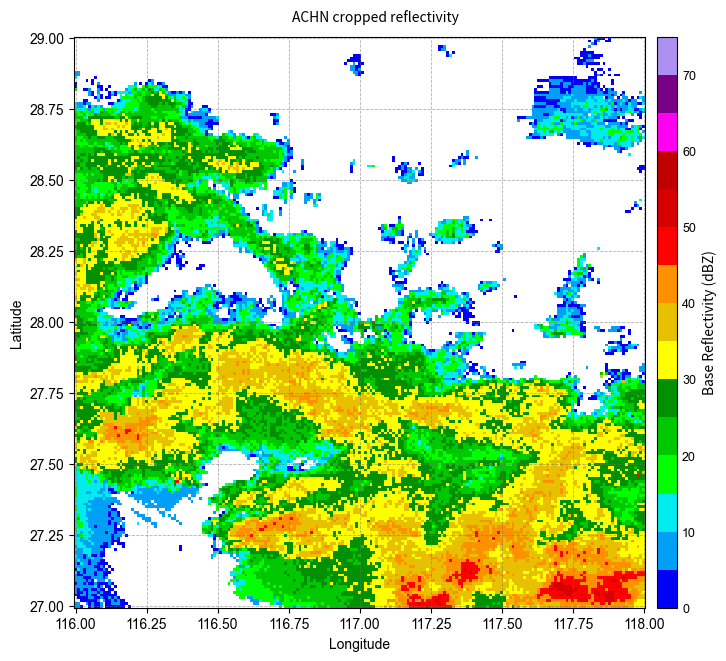

In [3]:
achn_grid = meb.read_griddata_from_nc(
    str(TEST_DATA_DIR / "ACHN_CREF000_20240612_070000.nc"),
    value_name="cref",
)

# 选取较小经纬度范围，避免邻域和小波算法在全国范围网格上运行过久。
achn_small = achn_grid.sel(
    lat=slice(27, 29),
    lon=slice(116, 118),
)

print(achn_small)
print("有效数据比例:", float(np.isfinite(achn_small.values).mean()))
print("反射率范围:", float(np.nanmin(achn_small.values)), float(np.nanmax(achn_small.values)))

# 保存裁剪的 ACHN 网格以供 CLI 使用（float32 无损，避免 meb 默认缩放量化）。
CLI_INPUT.mkdir(parents=True, exist_ok=True)
achn_small_file = CLI_INPUT / "ACHN_CREF000_20240612_070000_small.nc"
from radar_echo_classification.cli import save_echo_class_grid_to_netcdf

save_echo_class_grid_to_netcdf(achn_small, achn_small_file)
print("saved cropped ACHN:", achn_small_file)

# 将 meteva_base.grid_data 转换为 lon/lat 填色图所需的 numpy 数组。
achn_values = np.asarray(np.ma.filled(achn_small.values, np.nan), dtype=np.float32).squeeze()
achn_lon = np.asarray(achn_small.lon.values, dtype=np.float32)
achn_lat = np.asarray(achn_small.lat.values, dtype=np.float32)

from IPython.display import display

with plt.ioff():
    plot = plot_lonlat_field(
        achn_values,
        achn_lon,
        achn_lat,
        "REF",
        "ACHN cropped reflectivity",
    )
display(plot.fig)
plt.close(plot.fig)


In [4]:
achn_extent = [
    float(achn_small.lon.values[0]),
    float(achn_small.lon.values[-1]),
    float(achn_small.lat.values[0]),
    float(achn_small.lat.values[-1]),
]
print("achn_extent:", achn_extent)

achn_extent: [116.0, 118.0, 27.0, 29.0]


## 3. 估算水平分辨率

经纬度网格需要换算为米制距离。这里使用局地近似估算 `dx` 和 `dy`，并作为后续算法的显式输入。


In [5]:
from radar_echo_classification.src.utils._grid_utils import _get_dx_dy, get_xy_in_meters

# 与迁移算法同一套 Geod 局地近似，保证官方对照 Grid 的 dx/dy、x/y 一致。
dx, dy = _get_dx_dy(achn_small)
print("dx:", dx)
print("dy:", dy)


def build_pyart_grid_from_meb(grid_data, field_name="reflectivity"):
    data_2d = np.asarray(grid_data.values, dtype=np.float32).squeeze()
    masked_data = np.ma.masked_invalid(data_2d)[None, :, :]

    x_m, y_m = get_xy_in_meters(grid_data)
    x = np.asarray(x_m, dtype=np.float32)
    y = np.asarray(y_m, dtype=np.float32)
    z = np.asarray([float(grid_data.level.values[0])], dtype=np.float32)

    fields = {
        field_name: {
            "data": masked_data,
            "long_name": "reflectivity",
            "units": "dBZ",
        }
    }
    metadata = {"instrument_name": "ACHN_CREF"}
    origin_latitude = {"data": np.asarray([float(grid_data.lat.values[0])], dtype=np.float32)}
    origin_longitude = {"data": np.asarray([float(grid_data.lon.values[0])], dtype=np.float32)}
    origin_altitude = {"data": np.asarray([0.0], dtype=np.float32)}
    time = {"data": np.asarray([0.0], dtype=np.float64), "units": "seconds since 1970-01-01T00:00:00Z"}

    return pyart.core.Grid(
        time=time,
        fields=fields,
        metadata=metadata,
        origin_latitude=origin_latitude,
        origin_longitude=origin_longitude,
        origin_altitude=origin_altitude,
        x={"data": x, "units": "m"},
        y={"data": y, "units": "m"},
        z={"data": z, "units": "m"},
        projection={"proj": "pyart_aeqd", "_include_lon_0_lat_0": True},
    )


achn_refl_field = "reflectivity"
achn_pyart_grid = build_pyart_grid_from_meb(achn_small, field_name=achn_refl_field)
print("pyart grid shape:", achn_pyart_grid.fields[achn_refl_field]["data"].shape)

dx: 981.7935758794838
dy: 1111.95
pyart grid shape: (1, 201, 201)


## 4. Steiner 对流-层状分类（steiner_conv_strat）


In [6]:
# 原方法调用
official_steiner = pyart.retrieve.steiner_conv_strat(
    achn_pyart_grid,
    dx=dx,
    dy=dy,
    work_level=float(achn_small.level.values[0]),
    refl_field=achn_refl_field,
)

In [7]:
# 修改后算法调用
steiner_plugin = SteinerConvStratPlugin(
    dx=dx,
    dy=dy,
    work_level=float(achn_small.level.values[0]),
)
steiner_result = steiner_plugin(achn_small)

original_steiner_data = np.asarray(official_steiner["data"], dtype=np.float32).squeeze()
migrated_steiner_data = np.asarray(steiner_result.values, dtype=np.float32).squeeze()

print("official unique:", np.unique(original_steiner_data[np.isfinite(original_steiner_data)]))
print("migrated unique:", np.unique(migrated_steiner_data[np.isfinite(migrated_steiner_data)]))
print("max abs diff:", float(np.nanmax(np.abs(migrated_steiner_data - original_steiner_data))))

official unique: [0. 1. 2.]
migrated unique: [0. 1. 2.]
max abs diff: 0.0


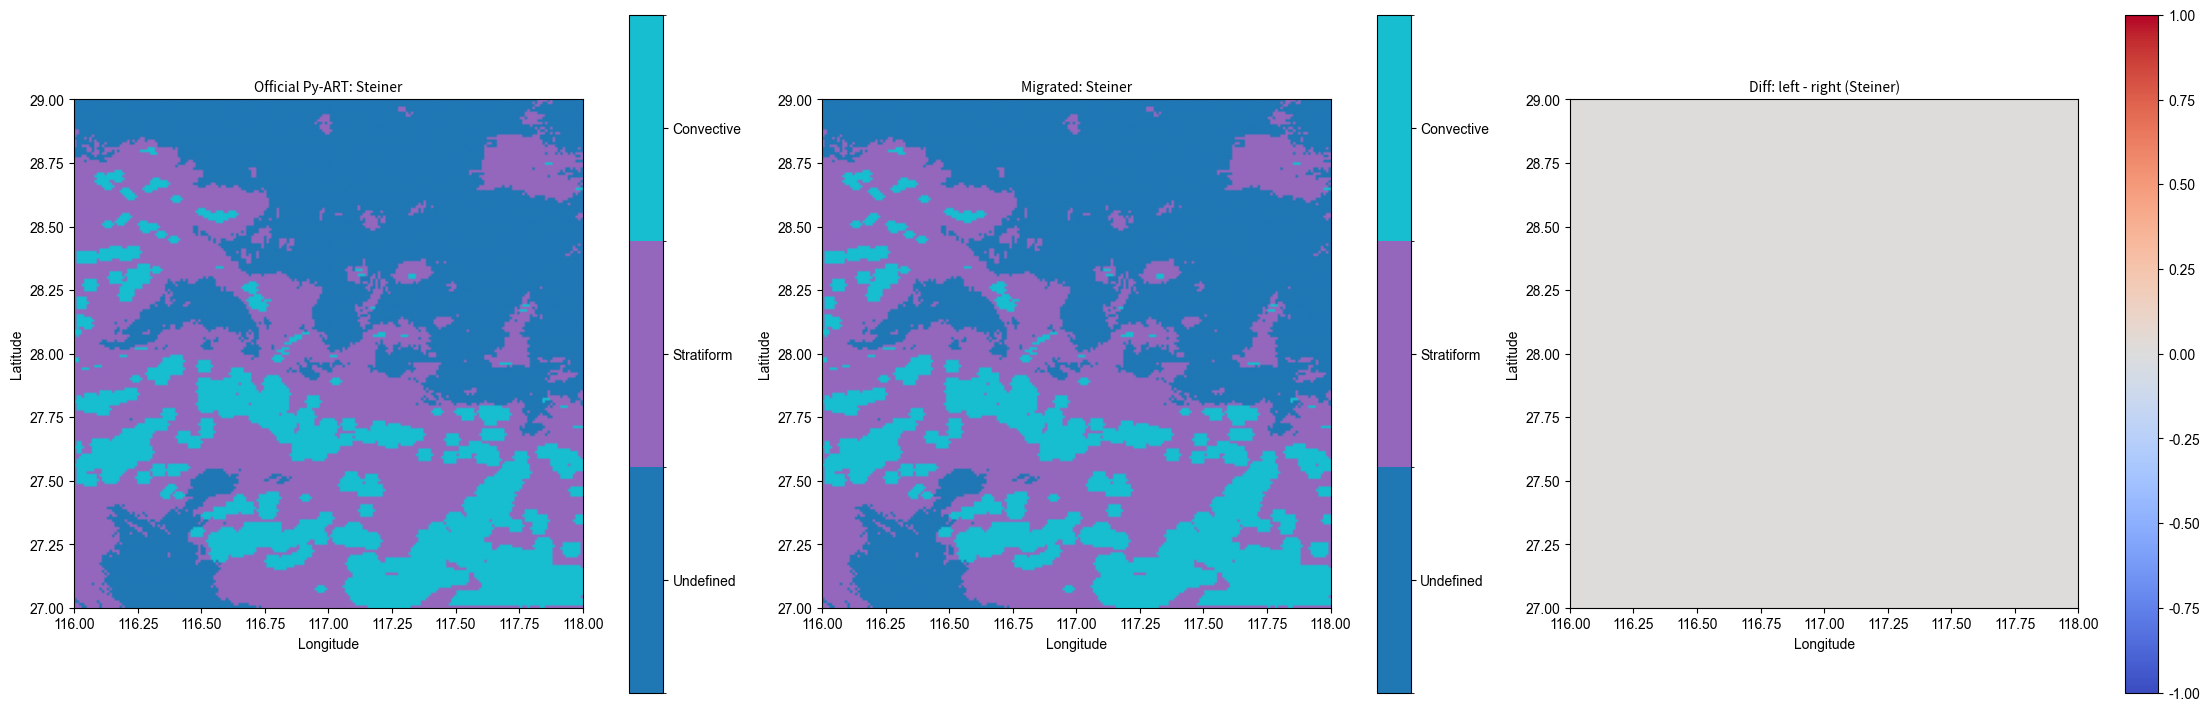

In [8]:
# 调用绘图函数对比结果
plot_categorical_comparison(
    "Steiner",
    original_steiner_data,
    migrated_steiner_data,
    achn_extent,
    class_labels=["Undefined", "Stratiform", "Convective"],
)


## 5. 特征识别（feature_detection）


In [9]:
# 原方法调用
official_feature = pyart.retrieve.feature_detection(
    achn_pyart_grid,
    dx=dx,
    dy=dy,
    level_m=float(achn_small.level.values[0]),
    field=achn_refl_field,
)

In [10]:
# 修改后算法调用
feature_plugin = FeatureDetectionPlugin(
    dx=dx,
    dy=dy,
    level_m=float(achn_small.level.values[0]),
)
feature_result = feature_plugin(achn_small)

original_feature_data = np.asarray(official_feature["feature_detection"]["data"], dtype=np.float32).squeeze()
migrated_feature_data = np.asarray(feature_result["feature_detection"].values, dtype=np.float32).squeeze()

print("official keys:", official_feature.keys())
print("migrated keys:", feature_result.keys())
print("official unique:", np.unique(original_feature_data[np.isfinite(original_feature_data)])[:20])
print("migrated unique:", np.unique(migrated_feature_data[np.isfinite(migrated_feature_data)])[:20])
print("max abs diff:", float(np.nanmax(np.abs(migrated_feature_data - original_feature_data))))



official keys: dict_keys(['feature_detection', 'feature_under', 'feature_over'])
migrated keys: dict_keys(['feature_detection', 'feature_under', 'feature_over'])
official unique: [0. 1. 2.]
migrated unique: [0. 1. 2.]
max abs diff: 0.0


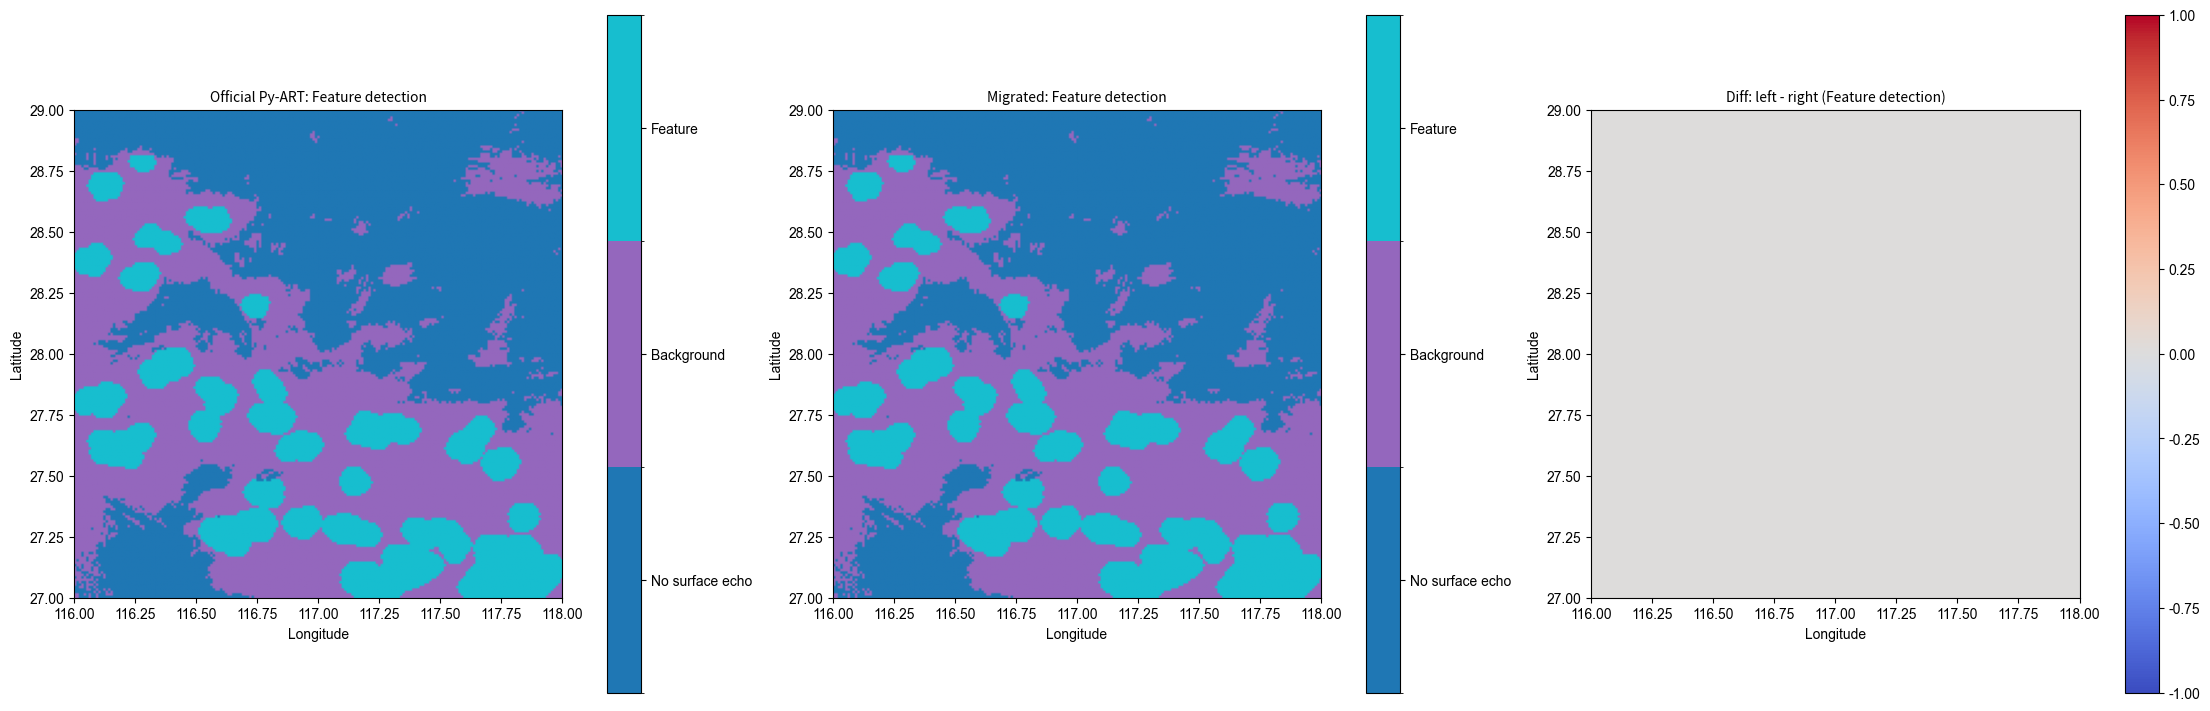

In [11]:
# 调用绘图函数对比结果
plot_categorical_comparison(
    "Feature detection",
    original_feature_data,
    migrated_feature_data,
    achn_extent,
    class_labels=["No surface echo", "Background", "Feature"],
)


### 5.1 SWX 样例验证（feature_detection）

本小节使用官方示例数据 `swx_20120520_0641.nc` 对修改后的特征识别算法进行结果验证对比。


swx_radar.fields['reflectivity_horizontal']['data'].shape: (400, 667)
swx_reflectivity_2d.shape: (400, 667)


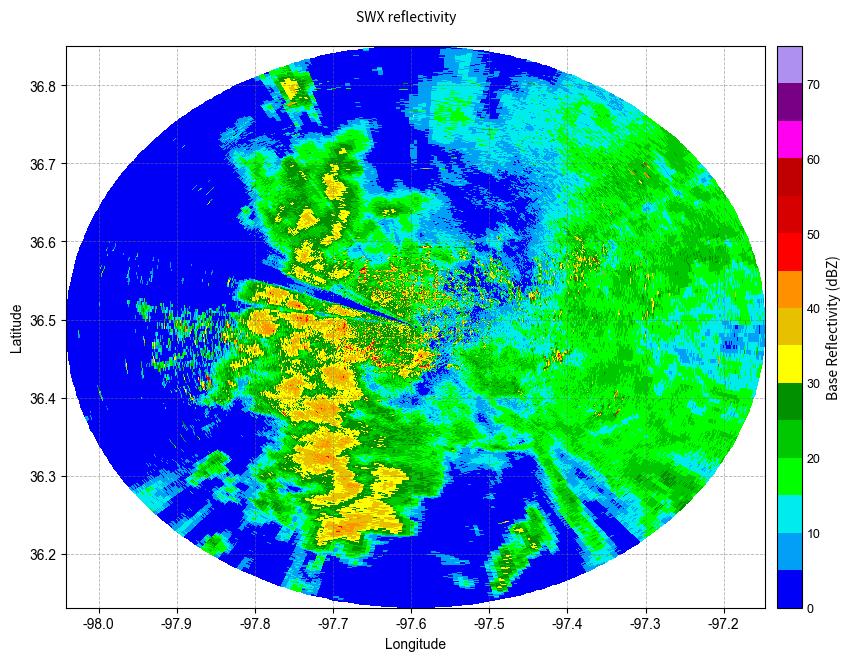

In [12]:
swx_file = TEST_DATA_DIR / "swx_20120520_0641.nc"

swx_radar = pyart.io.read(str(swx_file)).extract_sweeps([0])

swx_reflectivity_2d = np.ma.filled(
    np.asarray(swx_radar.fields["reflectivity_horizontal"]["data"], dtype=np.float32),
    np.nan,
)
print("swx_radar.fields['reflectivity_horizontal']['data'].shape:", swx_radar.fields["reflectivity_horizontal"]["data"].shape)
print("swx_reflectivity_2d.shape:", swx_reflectivity_2d.shape)
swx_gate_lat, swx_gate_lon, _ = swx_radar.get_gate_lat_lon_alt(0)
swx_gate_lat = np.asarray(swx_gate_lat, dtype=np.float32)
swx_gate_lon = np.asarray(swx_gate_lon, dtype=np.float32)

from IPython.display import display

with plt.ioff():
    plot = plot_lonlat_field(
        swx_reflectivity_2d,
        swx_gate_lon,
        swx_gate_lat,
        "REF",
        "SWX reflectivity",
    )
display(plot.fig)
plt.close(plot.fig)


swx official unique: [1. 2.]
swx migrated unique: [1. 2.]
swx max abs diff: 0.0


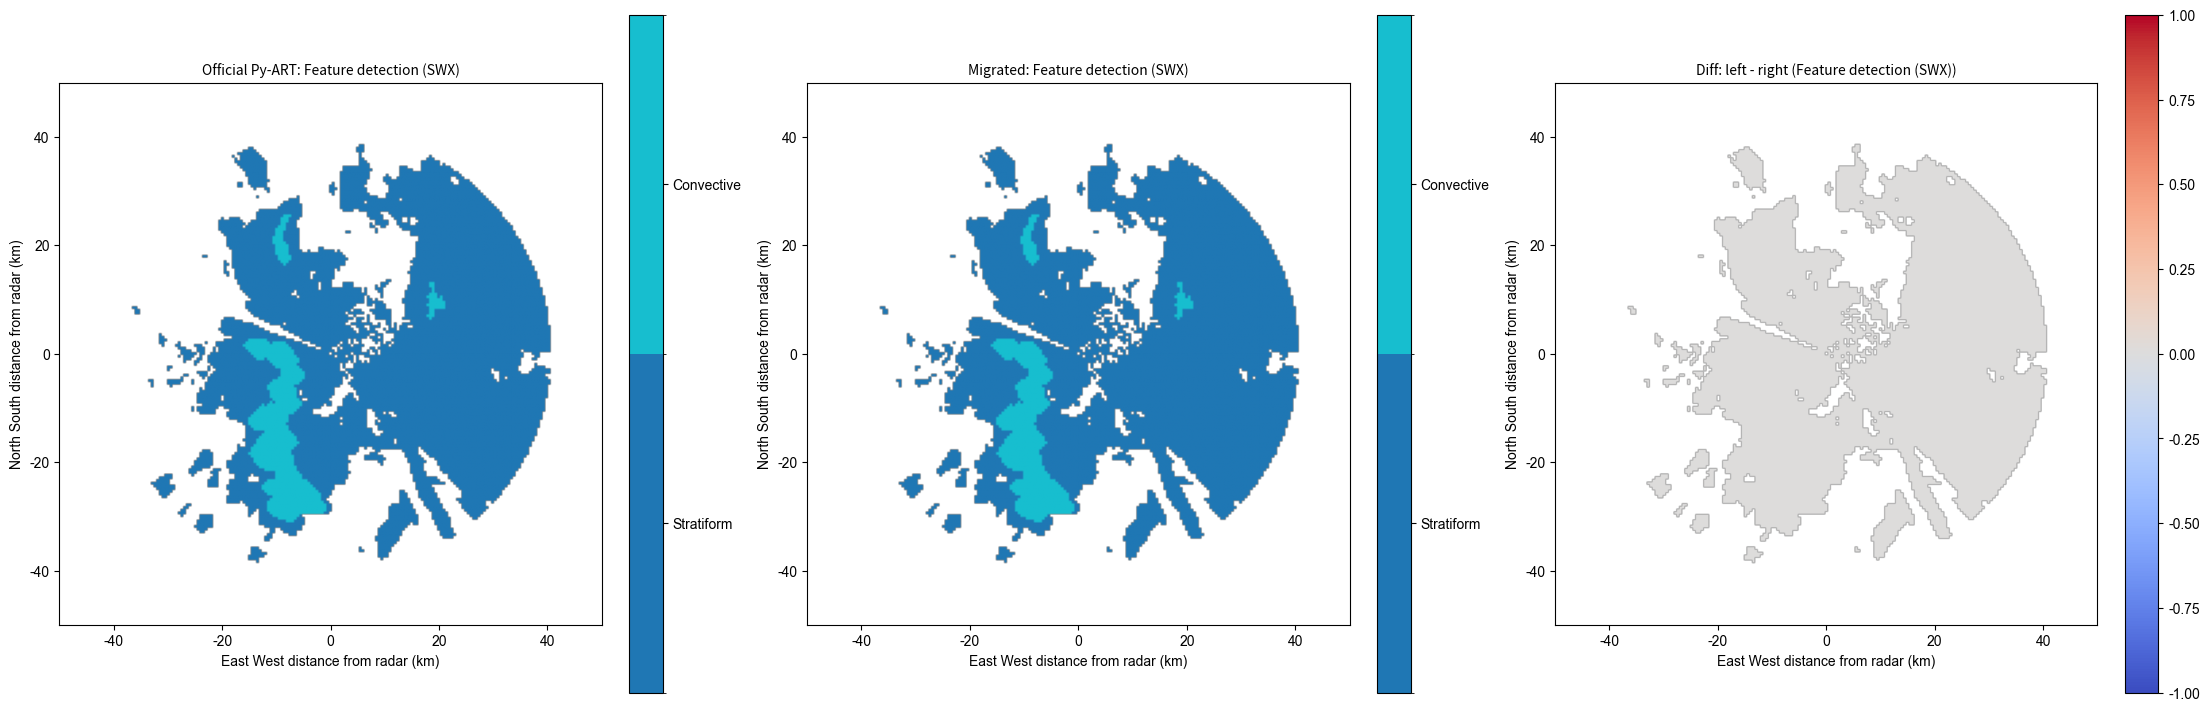

In [13]:
# 输入数据准备
swx_grid = pyart.map.grid_from_radars(
    (swx_radar,),
    grid_shape=(1, 201, 201),
    grid_limits=((0, 10000), (-50000.0, 50000.0), (-50000.0, 50000.0)),
    fields=["reflectivity_horizontal"],
    nb=1.5,
)
swx_dx = float(swx_grid.x["data"][1] - swx_grid.x["data"][0])
swx_dy = float(swx_grid.y["data"][1] - swx_grid.y["data"][0])
# 原方法调用
swx_feature_official = pyart.retrieve.feature_detection(
    swx_grid,
    # swx_dx,
    # swx_dy,
    field="reflectivity_horizontal",
    always_core_thres=40,
    bkg_rad_km=20,
    use_cosine=True,
    max_diff=5,
    zero_diff_cos_val=55,
    weak_echo_thres=10,
    max_rad_km=2,
)

swx_x = np.asarray(swx_grid.x["data"], dtype=np.float32) / 1000.0
swx_y = np.asarray(swx_grid.y["data"], dtype=np.float32) / 1000.0
swx_extent = [float(swx_x[0]), float(swx_x[-1]), float(swx_y[0]), float(swx_y[-1])]
# 插件算法输入准备
swx_meb_grid = meb.grid(
    [float(swx_x[0]), float(swx_x[-1]), float(np.median(np.diff(swx_x)))],
    [float(swx_y[0]), float(swx_y[-1]), float(np.median(np.diff(swx_y)))],
)
swx_reflectivity = np.ma.asarray(
    swx_grid.fields["reflectivity_horizontal"]["data"], dtype=np.float32
).filled(np.nan)
swx_meb_data = meb.grid_data(
    grid=swx_meb_grid,
    data=swx_reflectivity,
)
swx_meb_data.name = "reflectivity_horizontal"
# 修改算法调用
swx_feature_plugin = FeatureDetectionPlugin(
    dx=swx_dx,
    dy=swx_dy,
    level_m=0.0,
    always_core_thres=40,
    bkg_rad_km=20,
    use_cosine=True,
    max_diff=5,
    zero_diff_cos_val=55,
    weak_echo_thres=10,
    max_rad_km=2,
)
swx_feature_result = swx_feature_plugin(swx_meb_data)

swx_official_data = np.asarray(
    swx_feature_official["feature_detection"]["data"], dtype=np.float32
).squeeze()
swx_migrated_data = np.asarray(
    swx_feature_result["feature_detection"].values, dtype=np.float32
).squeeze()

swx_official_plot = swx_official_data.copy()
swx_migrated_plot = swx_migrated_data.copy()
for _arr in (swx_official_plot, swx_migrated_plot):
    _arr[(_arr == 0) | (_arr == 3)] = np.nan

print("swx official unique:", np.unique(swx_official_plot[np.isfinite(swx_official_plot)])[:20])
print("swx migrated unique:", np.unique(swx_migrated_plot[np.isfinite(swx_migrated_plot)])[:20])
print("swx max abs diff:", float(np.nanmax(np.abs(swx_migrated_plot - swx_official_plot))))

plot_categorical_comparison(
    "Feature detection (SWX)",
    swx_official_plot,
    swx_migrated_plot,
    swx_extent,
    x_label="East West distance from radar (km)",
    y_label="North South distance from radar (km)",
    class_labels=["Stratiform", "Convective"],
)


## 6. Raut 小波对流-层状分类（conv_strat_raut）


In [ ]:
def collapse_class_data(data):
    """Convert classification output to a 2D array."""
    arr = np.asarray(np.ma.asarray(data).astype(np.float32).filled(np.nan), dtype=np.float32).squeeze()
    if arr.ndim != 2:
        raise ValueError(f"Expected 2D classification array, got ndim={arr.ndim}")
    arr[arr <= -1.0e6] = np.nan
    arr[arr >= 1.0e6] = np.nan
    return arr

# 原方法调用
official_raut = pyart.retrieve.conv_strat_raut(
    achn_pyart_grid,
    achn_refl_field,
    cappi_level=0,
)
# 修改后算法调用
raut_plugin = ConvStratRautPlugin(
    cappi_level=0,
)
raut_result = raut_plugin(achn_small)

original_raut_data = collapse_class_data(official_raut["wt_reclass"]["data"])
migrated_raut_data = collapse_class_data(raut_result.values)
raut_valid = np.isfinite(original_raut_data) & np.isfinite(migrated_raut_data)

print("official unique:", np.unique(original_raut_data[np.isfinite(original_raut_data)]))
print("migrated unique:", np.unique(migrated_raut_data[np.isfinite(migrated_raut_data)]))
print("valid match ratio:", float(np.mean(original_raut_data[raut_valid] == migrated_raut_data[raut_valid])))
print("max abs diff:", float(np.nanmax(np.abs(migrated_raut_data[raut_valid] - original_raut_data[raut_valid]))))


official unique: [1. 2. 3.]
migrated unique: [1. 2. 3.]
valid match ratio: 1.0
max abs diff: 0.0


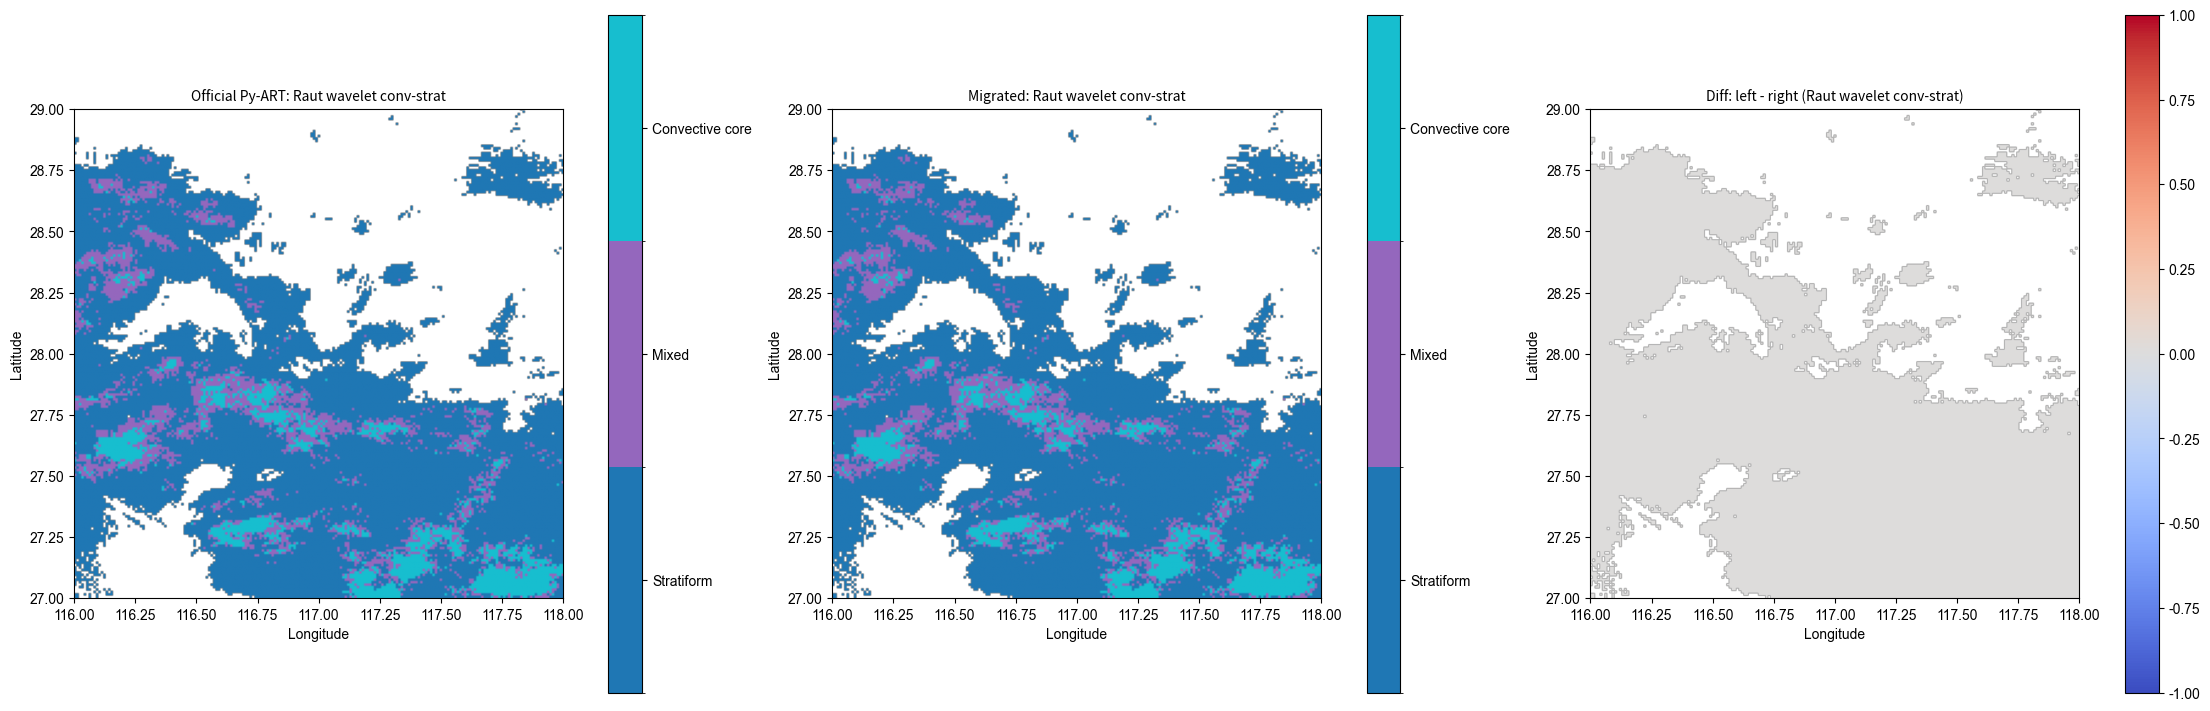

In [15]:
# 调用绘图函数对比结果
plot_categorical_comparison(
    "Raut wavelet conv-strat",
    original_raut_data,
    migrated_raut_data,
    achn_extent,
    class_labels=["Stratiform", "Mixed", "Convective core"],
)


## 7. 半监督水凝物分类（hydroclass_semisupervised）

本节使用官方 Py-ART 示例数据：`MLL2217907250U.003.nc` 和 `20220628072500_savevol_COSMO_LOOKUP_TEMP.nc`。官方预处理流程首先被重现，并将水凝物分类所需字段保存为 `meteva_base` 网格数据，用于迁移算法和后续的 CLI 验证。`specific_attenuation` 是衰减订正副产物，仅在本节用于展示，不再作为 echo_class CLI 输入写出。


In [16]:
def masked_to_nan(data, fill_value=None, missing_value=None):
    """Convert masked values and sentinel values to NaN."""
    arr = np.ma.asarray(data)
    if np.ma.isMaskedArray(arr):
        out = np.asarray(arr.data, dtype=np.float32)
        out[arr.mask] = np.nan
    else:
        out = np.asarray(arr, dtype=np.float32)

    for invalid in (fill_value, missing_value):
        if invalid is None:
            continue
        try:
            invalid_val = float(invalid)
        except (TypeError, ValueError):
            continue
        out[np.isclose(out, invalid_val, equal_nan=False)] = np.nan

    out[out <= -1.0e20] = np.nan
    out[out >= 1.0e20] = np.nan
    return out


def get_radar_frequency(radar_obj):
    """Read radar frequency from a Py-ART Radar object."""
    instrument_parameters = getattr(radar_obj, "instrument_parameters", None)
    if isinstance(instrument_parameters, dict):
        freq_item = instrument_parameters.get("frequency")
        if isinstance(freq_item, dict):
            freq_data = freq_item.get("data")
            if freq_data is not None:
                freq_value = np.asarray(freq_data, dtype=np.float64).squeeze()
                if np.size(freq_value) > 0:
                    return float(freq_value)
    raise ValueError("Cannot read frequency from radar instrument_parameters.")


def build_hydro_sweep_griddata(radar_obj, field_name, sweep_index=0, output_name=None):
    """Build one sweep as meb.grid_data for migrated-algorithm input."""
    sweep_slice = radar_obj.get_slice(sweep_index)
    azimuth = np.asarray(radar_obj.azimuth["data"][sweep_slice], dtype=np.float64)
    range_km = np.asarray(radar_obj.range["data"], dtype=np.float64) / 1000.0

    az_step = float(np.nanmedian(np.abs(np.diff(azimuth)))) if azimuth.size > 1 else 1.0
    range_step = float(np.nanmedian(np.abs(np.diff(range_km)))) if range_km.size > 1 else 1.0

    sweep_grid = meb.grid(
        [float(range_km[0]), float(range_km[-1]), range_step],
        [float(azimuth[0]), float(azimuth[-1]), az_step],
    )

    field_meta = radar_obj.fields[field_name]
    field_data = masked_to_nan(
        field_meta["data"][sweep_slice],
        fill_value=field_meta.get("_FillValue"),
        missing_value=field_meta.get("missing_value"),
    )

    grid_data = meb.grid_data(grid=sweep_grid, data=field_data.astype(np.float32, copy=False))
    grid_data.name = output_name or field_name
    if field_meta.get("long_name") is not None:
        grid_data.attrs["long_name"] = field_meta["long_name"]
    if field_meta.get("units") is not None:
        grid_data.attrs["units"] = field_meta["units"]
    if field_meta.get("_FillValue") is not None:
        grid_data.attrs["_FillValue"] = field_meta["_FillValue"]
    if field_meta.get("missing_value") is not None:
        grid_data.attrs["missing_value"] = field_meta["missing_value"]
    return grid_data, azimuth, range_km, sweep_slice



In [17]:
hydro_radar_file = TEST_DATA_DIR / "MLL2217907250U.003.nc"  # 雷达数据
hydro_temp_file = TEST_DATA_DIR / "20220628072500_savevol_COSMO_LOOKUP_TEMP.nc"  # 温度数据
hydro_sweep_index = 0  #仰角索引，本数据只有一个仰角层
hydro_refl_field = "corrected_reflectivity"  # 衰减订正后的反射率字段名
hydro_zdr_field = "corrected_differential_reflectivity"  # 衰减订正后的差分反射率字段名
hydro_kdp_field = "specific_differential_phase"  # KDP 字段名
hydro_rhv_field = "uncorrected_cross_correlation_ratio"  # 互相关系数字段名
hydro_temp_field = "temperature"  # 温度字段名
hydro_att_field = "specific_attenuation"  # 比衰减字段名


# 复现官方 Py-ART 示例的预处理流程。
hydro_radar = pyart.io.read_cfradial(str(hydro_radar_file))
hydro_temp_radar = pyart.io.read_cfradial(str(hydro_temp_file))
hydro_radar.add_field(hydro_temp_field, hydro_temp_radar.fields[hydro_temp_field])

spec_at, pia, cor_z, spec_diff_at, pida, cor_zdr = pyart.correct.calculate_attenuation_zphi(
    hydro_radar,
    phidp_field="uncorrected_differential_phase",
    temp_field=hydro_temp_field,
    temp_ref=hydro_temp_field,
)
hydro_radar.add_field(hydro_refl_field, cor_z)
hydro_radar.add_field(hydro_zdr_field, cor_zdr)
hydro_radar.add_field("specific_attenuation", spec_at)

kdp, _, _ = pyart.retrieve.kdp_maesaka(
    hydro_radar, psidp_field="uncorrected_differential_phase"
)
hydro_radar.add_field(hydro_kdp_field, kdp)

hydro_frequency = get_radar_frequency(hydro_radar)
print("Radar frequency (GHz):", hydro_frequency / 1e9)

# 仅保存迁移版水凝物分类所需的 meteva_base 网格输入。
hydro_refl_grid, hydro_azimuth, hydro_range_km, hydro_sweep_slice = build_hydro_sweep_griddata(
    hydro_radar, hydro_refl_field, sweep_index=hydro_sweep_index, output_name="corrected_reflectivity"
)
hydro_zdr_grid, _, _, _ = build_hydro_sweep_griddata(
    hydro_radar, hydro_zdr_field, sweep_index=hydro_sweep_index, output_name="corrected_differential_reflectivity"
)
hydro_kdp_grid, _, _, _ = build_hydro_sweep_griddata(
    hydro_radar, hydro_kdp_field, sweep_index=hydro_sweep_index, output_name="specific_differential_phase"
)
hydro_rhv_grid, _, _, _ = build_hydro_sweep_griddata(
    hydro_radar, hydro_rhv_field, sweep_index=hydro_sweep_index, output_name="uncorrected_cross_correlation_ratio"
)
hydro_temp_grid, _, _, _ = build_hydro_sweep_griddata(
    hydro_radar, hydro_temp_field, sweep_index=hydro_sweep_index, output_name="temperature"
)
# CLI 示例输入：用 float32 + CF 缺测写盘，避免 meb 默认 int32/scale_factor=0.001
# 量化导致边界格点分类翻转。
from radar_echo_classification.cli import save_echo_class_grid_to_netcdf

hydro_input_files = {
    "corrected_reflectivity": hydro_refl_grid,
    "corrected_differential_reflectivity": hydro_zdr_grid,
    "specific_differential_phase": hydro_kdp_grid,
    "uncorrected_cross_correlation_ratio": hydro_rhv_grid,
    "temperature": hydro_temp_grid,
}
for field_name, grid_data in hydro_input_files.items():
    save_path = CLI_INPUT / f"hydro_{field_name}.nc"
    save_echo_class_grid_to_netcdf(grid_data, save_path)
    print("saved:", save_path)

print("Official example data are ready.")
print("meb input directory:", CLI_INPUT)


Radar frequency (GHz): 5.450771968
saved: d:\workspace\pyart_nimm\echo_class\test_data\echo_class\cli_input\hydro_corrected_reflectivity.nc
saved: d:\workspace\pyart_nimm\echo_class\test_data\echo_class\cli_input\hydro_corrected_differential_reflectivity.nc
saved: d:\workspace\pyart_nimm\echo_class\test_data\echo_class\cli_input\hydro_specific_differential_phase.nc
saved: d:\workspace\pyart_nimm\echo_class\test_data\echo_class\cli_input\hydro_uncorrected_cross_correlation_ratio.nc
saved: d:\workspace\pyart_nimm\echo_class\test_data\echo_class\cli_input\hydro_temperature.nc
Official example data are ready.
meb input directory: d:\workspace\pyart_nimm\echo_class\test_data\echo_class\cli_input


数据展示

In [18]:
from cinrad.visualize.gpf import _cmap

hydro_site_lon = float(np.nanmean(hydro_radar.longitude["data"]))
hydro_site_lat = float(np.nanmean(hydro_radar.latitude["data"]))
hydro_gate_lat, hydro_gate_lon, _ = hydro_radar.get_gate_lat_lon_alt(hydro_sweep_index)

def _get_sweep_field_values(radar_obj, field_name, sweep_slice):
    field_meta = radar_obj.fields[field_name]
    return masked_to_nan(
        field_meta["data"][sweep_slice],
        fill_value=field_meta.get("_FillValue"),
        missing_value=field_meta.get("missing_value"),
    )

hydro_refl_2d = _get_sweep_field_values(hydro_radar, hydro_refl_field, hydro_sweep_slice)
hydro_zdr_2d = _get_sweep_field_values(hydro_radar, hydro_zdr_field, hydro_sweep_slice)
hydro_kdp_2d = _get_sweep_field_values(hydro_radar, hydro_kdp_field, hydro_sweep_slice)
hydro_rhv_2d = _get_sweep_field_values(hydro_radar, hydro_rhv_field, hydro_sweep_slice)
hydro_temp_2d = _get_sweep_field_values(hydro_radar, hydro_temp_field, hydro_sweep_slice)
hydro_att_2d = _get_sweep_field_values(hydro_radar, hydro_att_field, hydro_sweep_slice)

hydro_input_specs = [
    ("REF", hydro_refl_2d, "Cinrad style: Corrected reflectivity", None, None, None),
    ("ZDR", hydro_zdr_2d, "Cinrad style: Corrected ZDR", None, None, None),
    ("KDP", hydro_kdp_2d, "Cinrad style: Specific differential phase", None, None, None),
    ("RHO", hydro_rhv_2d, "Cinrad style: Cross-correlation ratio", None, None, None),
    (
        "TEMP",
        hydro_temp_2d,
        "Cinrad style: Temperature",
        "coolwarm",
        Normalize(vmin=-40.0, vmax=20.0),
        [-40, -30, -20, -10, 0, 10, 20],
    ),
    (
        "AT",
        hydro_att_2d,
        "Cinrad style: Specific attenuation",
        _cmap("REF")["cmap"],
        Normalize(vmin=0.0, vmax=1.0),
        [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    ),
]


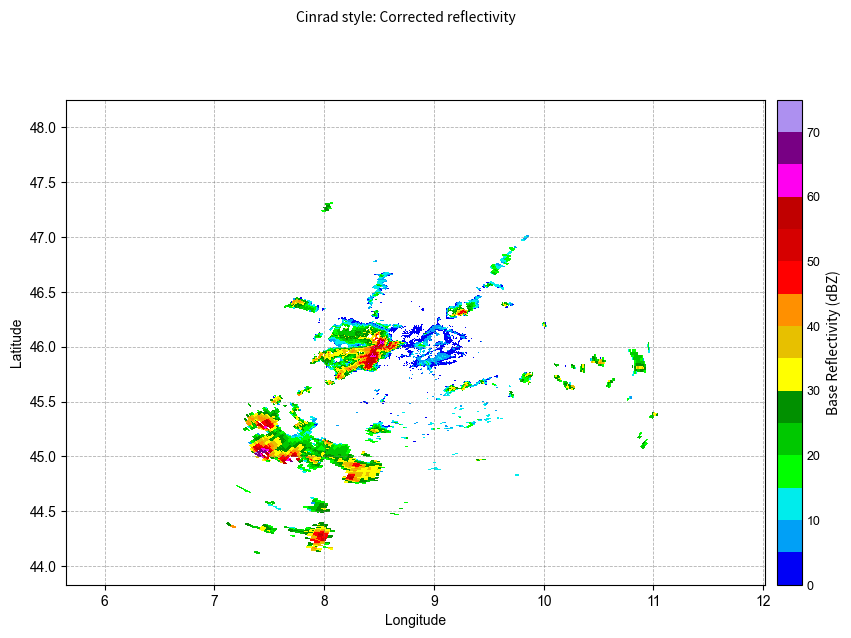

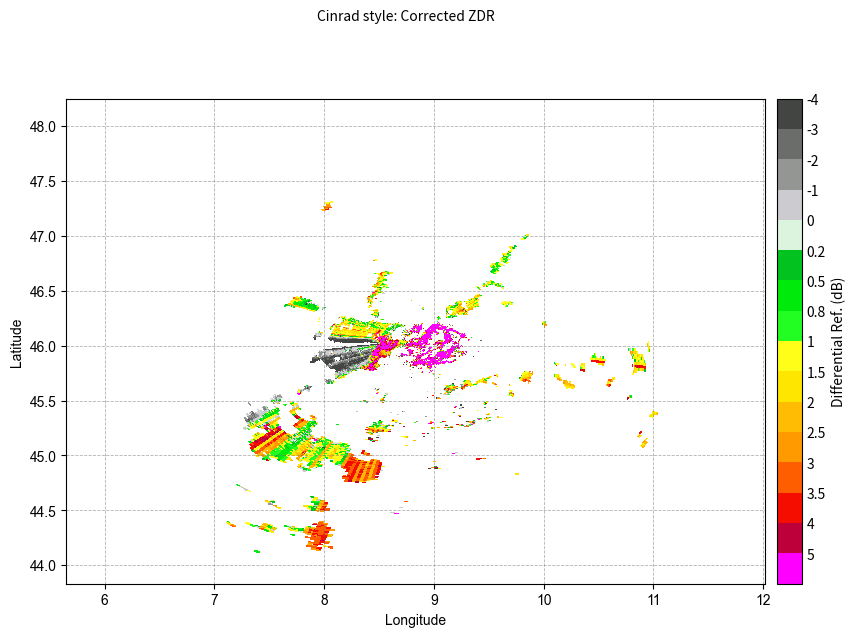

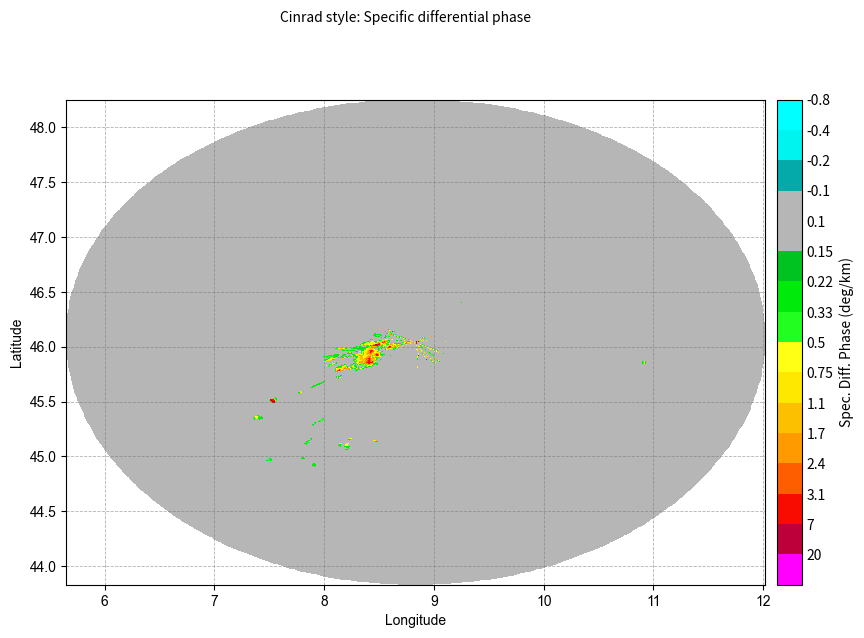

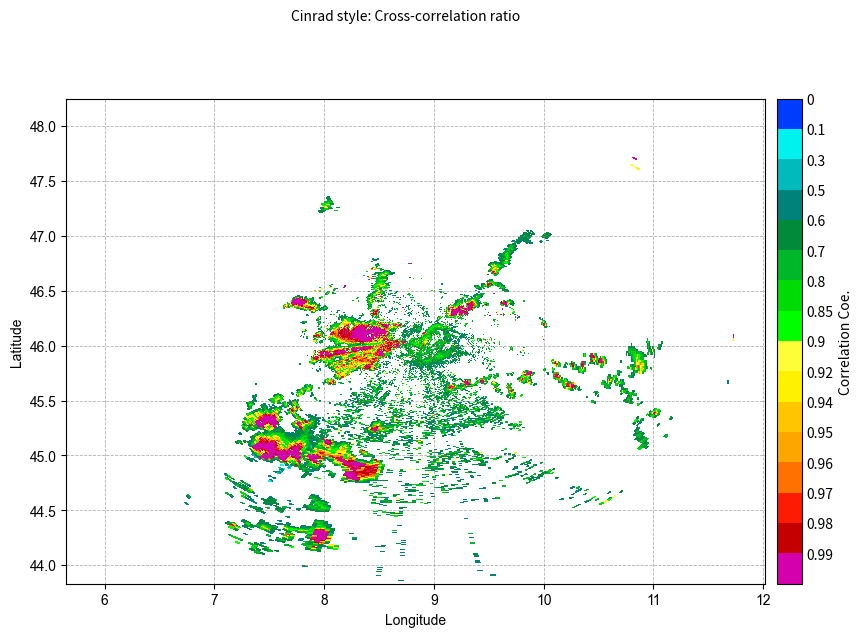

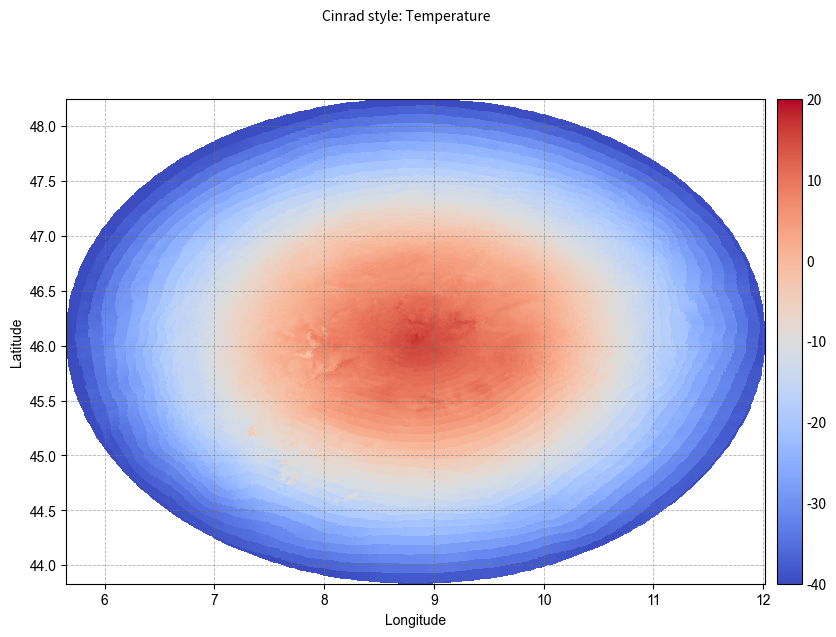

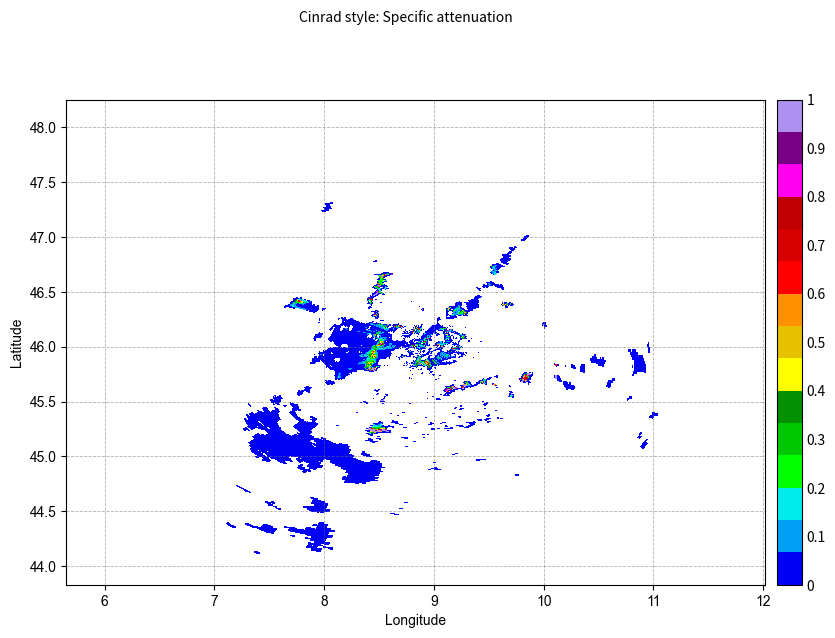

In [19]:
for field_name, values, title, cmap, norm, ticks in hydro_input_specs:
    kwargs = {}
    if cmap is not None:
        kwargs["cmap"] = cmap
    if norm is not None:
        kwargs["norm"] = norm
    if ticks is not None:
        kwargs["cbar_tick_labels"] = [f"{tick:g}" for tick in ticks]

    with plt.ioff():
        plot = plot_lonlat_field(
            values,
            hydro_gate_lon,
            hydro_gate_lat,
            field_name,
            title,
            **kwargs,
        )
    display(plot.fig)
    plt.close(plot.fig)


### 7.1 插件类结果与原算法结果对比

使用与官方示例相同的派生字段运行 `HydroclassSemisupervisedPlugin`，然后将迁移后的输出与同一扫描的官方 Py-ART 结果进行比较。


match ratio: 1.0
different grid count: 0
valid grid count: 177120
max absolute difference: 0.0


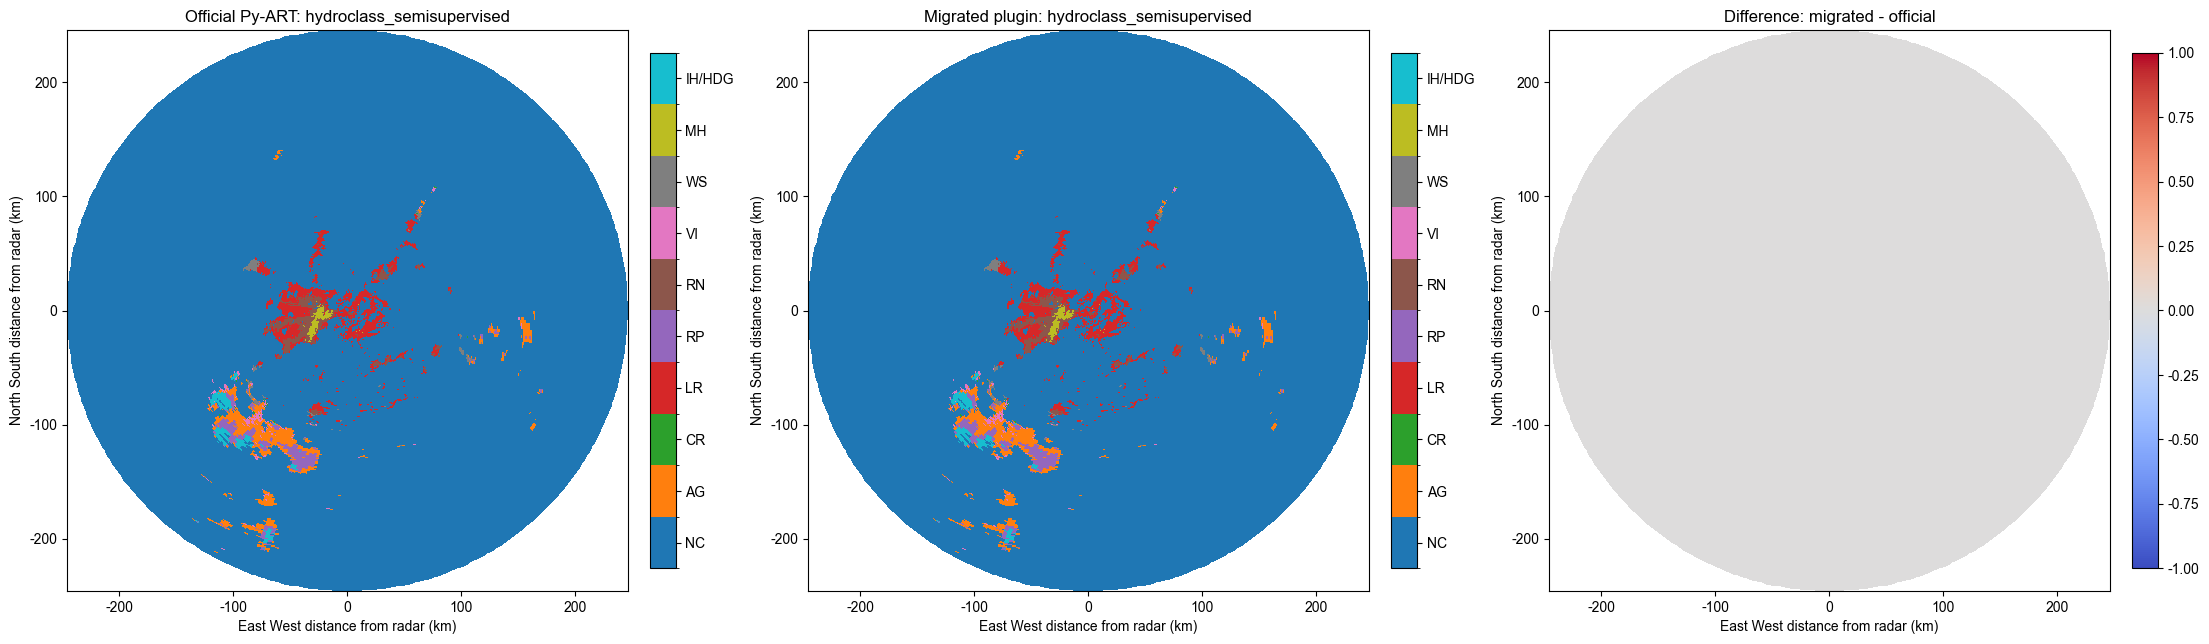

In [20]:
#原算法调用
hydro_official = pyart.retrieve.hydroclass_semisupervised(
    hydro_radar,
    refl_field=hydro_refl_field,
    zdr_field=hydro_zdr_field,
    kdp_field=hydro_kdp_field,
    rhv_field=hydro_rhv_field,
    temp_field=hydro_temp_field,
)["hydro"]

#调用水凝物分类算法
hydro_plugin = HydroclassSemisupervisedPlugin(
    radar_freq=hydro_frequency,
)
hydro_plugin_result = hydro_plugin(
    refl=hydro_refl_grid,
    zdr=hydro_zdr_grid,
    rhv=hydro_rhv_grid,
    kdp=hydro_kdp_grid,
    temp=hydro_temp_grid,
)

official_hydro_data = collapse_class_data(hydro_official["data"][hydro_sweep_slice])
migrated_hydro_data = collapse_class_data(hydro_plugin_result["hydro"])

if official_hydro_data.shape != migrated_hydro_data.shape:
    raise ValueError(
        f"Shape mismatch: official={official_hydro_data.shape}, migrated={migrated_hydro_data.shape}"
    )

valid_mask = np.isfinite(official_hydro_data) & np.isfinite(migrated_hydro_data)
hydro_diff = np.full_like(migrated_hydro_data, np.nan, dtype=np.float32)
hydro_diff[valid_mask] = migrated_hydro_data[valid_mask] - official_hydro_data[valid_mask]

match_ratio = float(np.mean(migrated_hydro_data[valid_mask] == official_hydro_data[valid_mask])) if np.any(valid_mask) else np.nan
diff_count = int(np.count_nonzero((migrated_hydro_data != official_hydro_data) & valid_mask))
valid_count = int(np.count_nonzero(valid_mask))
max_abs_diff = float(np.nanmax(np.abs(hydro_diff))) if np.any(valid_mask) else np.nan

print("match ratio:", match_ratio)
print("different grid count:", diff_count)
print("valid grid count:", valid_count)
print("max absolute difference:", max_abs_diff)

hydro_labels = ["NC", "AG", "CR", "LR", "RP", "RN", "VI", "WS", "MH", "IH/HDG"]
hydro_ticks = np.arange(len(hydro_labels))
hydro_boundaries = np.arange(-0.5, len(hydro_labels), 1.0)
hydro_cmap = plt.get_cmap("tab10", len(hydro_labels))
hydro_norm = BoundaryNorm(hydro_boundaries, hydro_cmap.N)

hydro_gate_x, hydro_gate_y, _ = hydro_radar.get_gate_x_y_z(hydro_sweep_index)
hydro_gate_x_km = np.asarray(hydro_gate_x, dtype=np.float32) / 1000.0
hydro_gate_y_km = np.asarray(hydro_gate_y, dtype=np.float32) / 1000.0

fig, axes = plt.subplots(1, 3, figsize=(22, 7), constrained_layout=True)
plot_specs = [
    (axes[0], official_hydro_data, "Official Py-ART: hydroclass_semisupervised"),
    (axes[1], migrated_hydro_data, "Migrated plugin: hydroclass_semisupervised"),
    (axes[2], hydro_diff, "Difference: migrated - official"),
]

for ax, data, title in plot_specs[:2]:
    im = ax.pcolormesh(
        hydro_gate_x_km,
        hydro_gate_y_km,
        data,
        shading="auto",
        cmap=hydro_cmap,
        norm=hydro_norm,
    )
    ax.set_title(title)
    ax.set_xlabel("East West distance from radar (km)")
    ax.set_ylabel("North South distance from radar (km)")
    ax.set_aspect("equal", "box")
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_ticks(hydro_ticks)
    cb.set_ticklabels(hydro_labels)

max_diff = float(np.nanmax(np.abs(hydro_diff))) if np.isfinite(hydro_diff).any() else 1.0
max_diff = max(max_diff, 1.0)
im2 = axes[2].pcolormesh(
    hydro_gate_x_km,
    hydro_gate_y_km,
    hydro_diff,
    shading="auto",
    cmap="coolwarm",
    vmin=-max_diff,
    vmax=max_diff,
)
axes[2].set_title("Difference: migrated - official")
axes[2].set_xlabel("East West distance from radar (km)")
axes[2].set_ylabel("North South distance from radar (km)")
axes[2].set_aspect("equal", "box")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.show()

# For info
# NC = not classified
# AG = aggregates
# CR = ice crystals
# LR = light rain
# RP = rimed particles
# RN = rain
# VI = vertically oriented ice
# WS = wet snow
# MH = melting hail
# IH/HDG = dry hail / high density graupel


## 8. CLI 应用示例

各算法 CLI 示例脚本位于 `radar_echo_classification/cli/*_main.py`，统一入口为 `process()`。下面调用各算法 CLI，输入来自 `cli_input/`，输出写入 `cli_output/`。


In [21]:
import xarray as xr


def read_cli_data_2d(path: Path, value_name: str = None) -> np.ndarray:
    if not path.exists():
        raise FileNotFoundError(f"未找到 CLI 输出: {path}")

    # 优先使用 xarray 读取，避免自动将填充值 0 转换为缺测
    # 因为原始算法输出中 0 也可能是有效分类标签
    try:
        # mask_and_scale=False 避免把分类标签 0 当成缺测；
        # 若文件带有 scale_factor（旧版 meb 写出），再手动还原物理值。
        with xr.open_dataset(path, mask_and_scale=False) as ds:
            var_name = value_name or list(ds.data_vars)[0]
            if var_name not in ds.data_vars:
                raise KeyError(f"{var_name!r} not found in {path}")
            arr = np.asarray(ds[var_name].values, dtype=np.float32).squeeze()
            scale_factor = ds[var_name].encoding.get("scale_factor")
            add_offset = ds[var_name].encoding.get("add_offset", 0.0)
            if scale_factor is not None:
                arr = arr.astype(np.float32, copy=False) * float(scale_factor) + float(add_offset)
        # 释放 netCDF 句柄，避免 Windows 下随后覆盖同名文件失败
        try:
            from xarray.backends.file_manager import FILE_CACHE
            FILE_CACHE.clear()
        except Exception:
            pass
    except Exception:
        da = meb.read_griddata_from_nc(str(path), value_name=value_name)
        arr = np.asarray(da.values, dtype=np.float32).squeeze()

    arr = arr.copy()
    arr[arr <= -1.0e20] = np.nan
    arr[arr >= 1.0e20] = np.nan
    if arr.ndim == 6:
        arr = arr[0, 0, 0, 0, :, :]
    if arr.ndim != 2:
        raise ValueError(f"意外的维度数={arr.ndim} 对于 {path}")
    return arr


CLI_INPUT.mkdir(parents=True, exist_ok=True)
CLI_OUTPUT.mkdir(parents=True, exist_ok=True)

# 从前面单元格中获取的 ACHN 范围
achn_extent = [
    float(achn_small.lon.values[0]),
    float(achn_small.lon.values[-1]),
    float(achn_small.lat.values[0]),
    float(achn_small.lat.values[-1]),
]


### 8.1 steiner_conv_strat


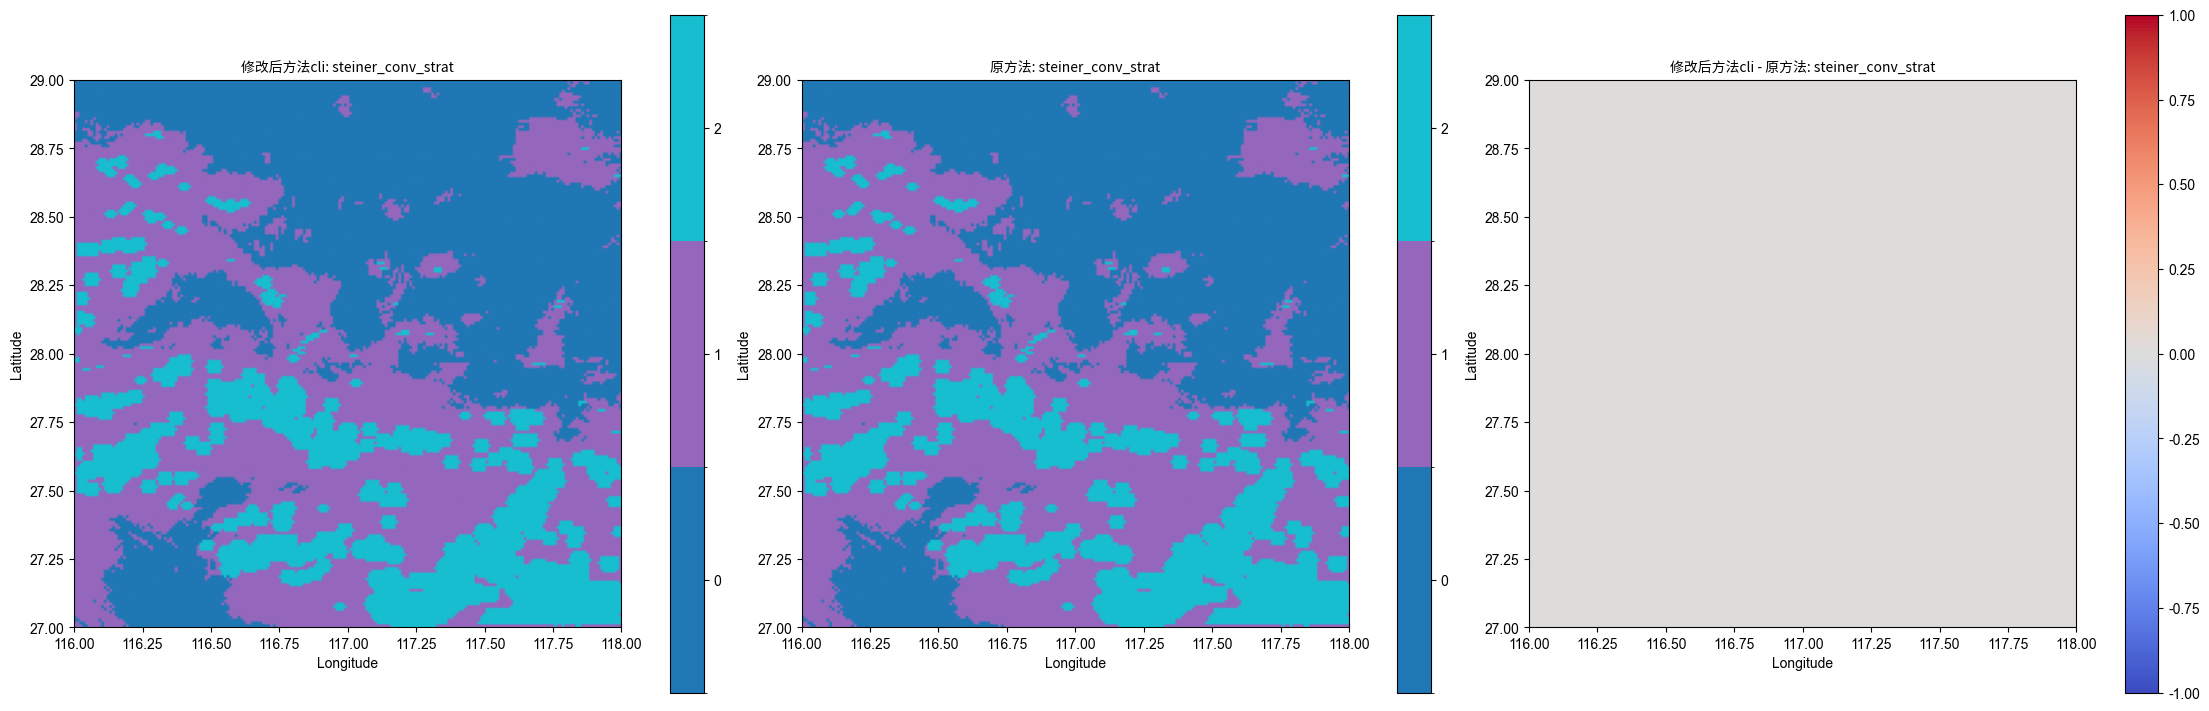

[steiner_conv_strat] CLI vs plugin match: 1.0


In [22]:
from radar_echo_classification.cli.steiner_conv_strat_main import process as steiner_conv_strat

steiner_conv_strat(
    str(CLI_INPUT / "ACHN_CREF000_20240612_070000_small.nc"),
    work_level=0.0,
    output_path=str(CLI_OUTPUT / "achn_steiner_cli.nc"),
)

# SteinerConvStrat
steiner_cli_data = read_cli_data_2d(CLI_OUTPUT / "achn_steiner_cli.nc")
plot_categorical_comparison(
    "steiner_conv_strat",
    steiner_cli_data,
    np.asarray(original_steiner_data, dtype=np.float32),
    achn_extent,
    left_title="修改后方法cli: steiner_conv_strat",
    right_title="原方法: steiner_conv_strat",
    diff_title="修改后方法cli - 原方法: steiner_conv_strat",
)
valid = np.isfinite(steiner_cli_data) & np.isfinite(np.asarray(migrated_steiner_data, dtype=np.float32))
print("[steiner_conv_strat] CLI vs plugin match:", float(np.mean((steiner_cli_data == np.asarray(migrated_steiner_data, dtype=np.float32))[valid].astype(np.float32))))


### 8.2 feature_detection


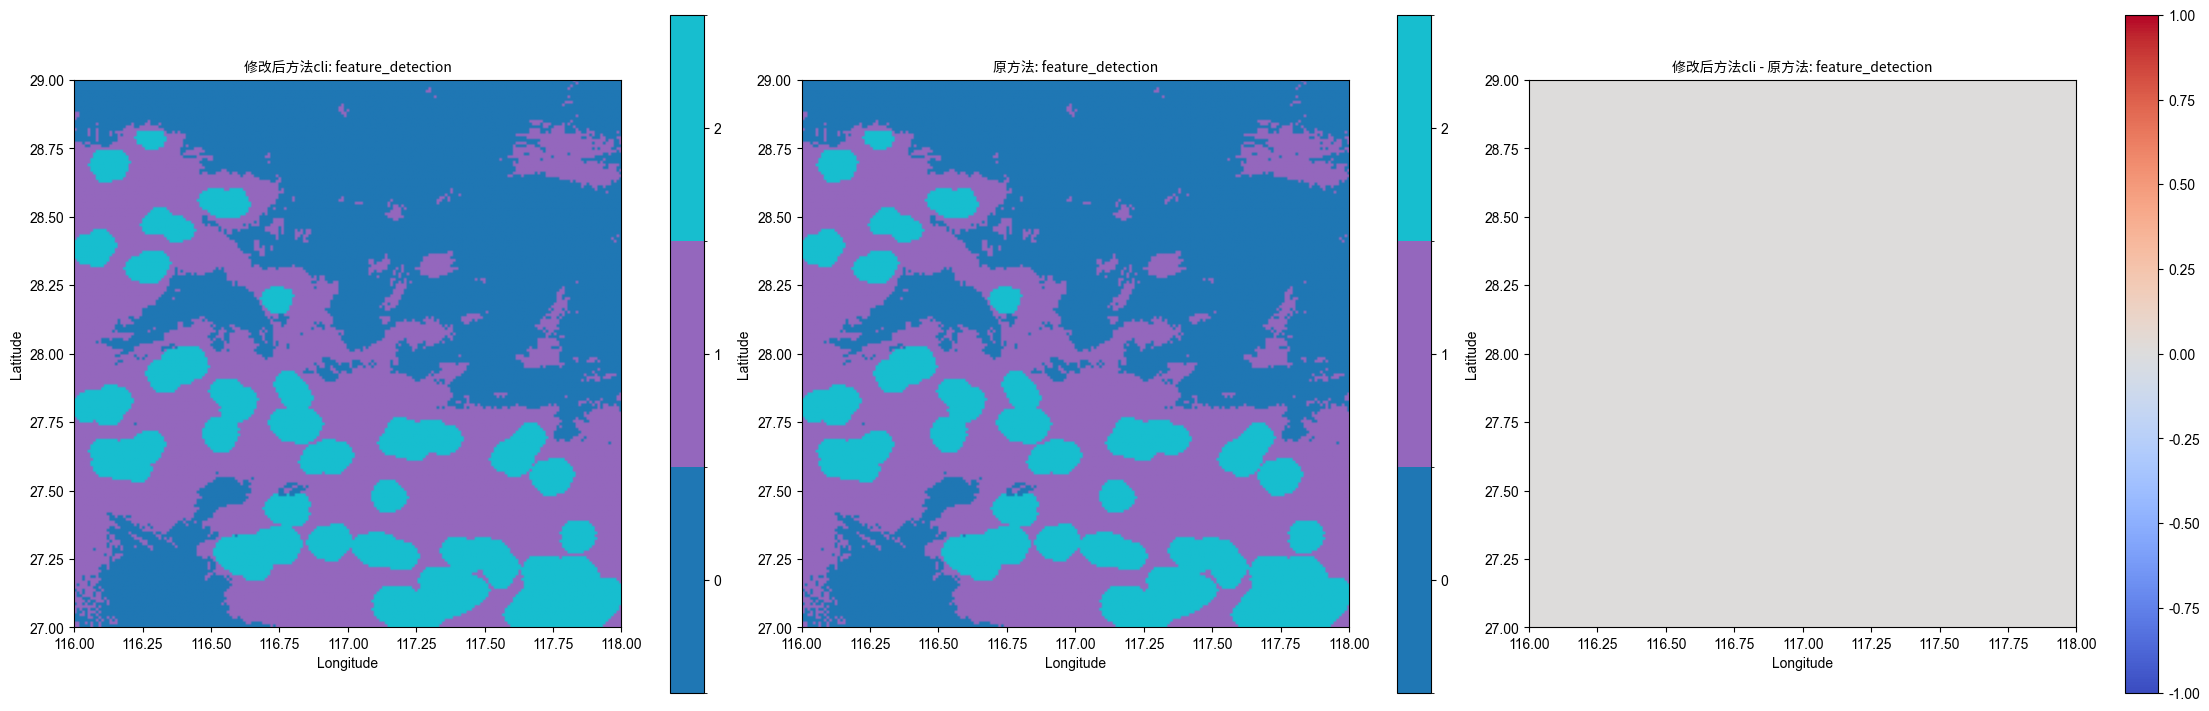

[feature_detection] CLI vs plugin match: 1.0


In [23]:
from radar_echo_classification.cli.feature_detection_main import process as feature_detection

# 与前面 FeatureDetectionPlugin / 原版验证一致：算法参数用默认值（binary_close=False 等）
feature_detection(
    str(CLI_INPUT / "ACHN_CREF000_20240612_070000_small.nc"),
    level_m=0.0,
    result_key="feature_detection",
    output_path=str(CLI_OUTPUT / "achn_feature_cli.nc"),
)

# Feature detection
feature_cli_data = read_cli_data_2d(CLI_OUTPUT / "achn_feature_cli.nc")
plot_categorical_comparison(
    "feature_detection",
    feature_cli_data,
    np.asarray(original_feature_data, dtype=np.float32),
    achn_extent,
    left_title="修改后方法cli: feature_detection",
    right_title="原方法: feature_detection",
    diff_title="修改后方法cli - 原方法: feature_detection",
)
valid = np.isfinite(feature_cli_data) & np.isfinite(np.asarray(migrated_feature_data, dtype=np.float32))
print("[feature_detection] CLI vs plugin match:", float(np.mean((feature_cli_data == np.asarray(migrated_feature_data, dtype=np.float32))[valid].astype(np.float32))))


### 8.3 conv_strat_raut


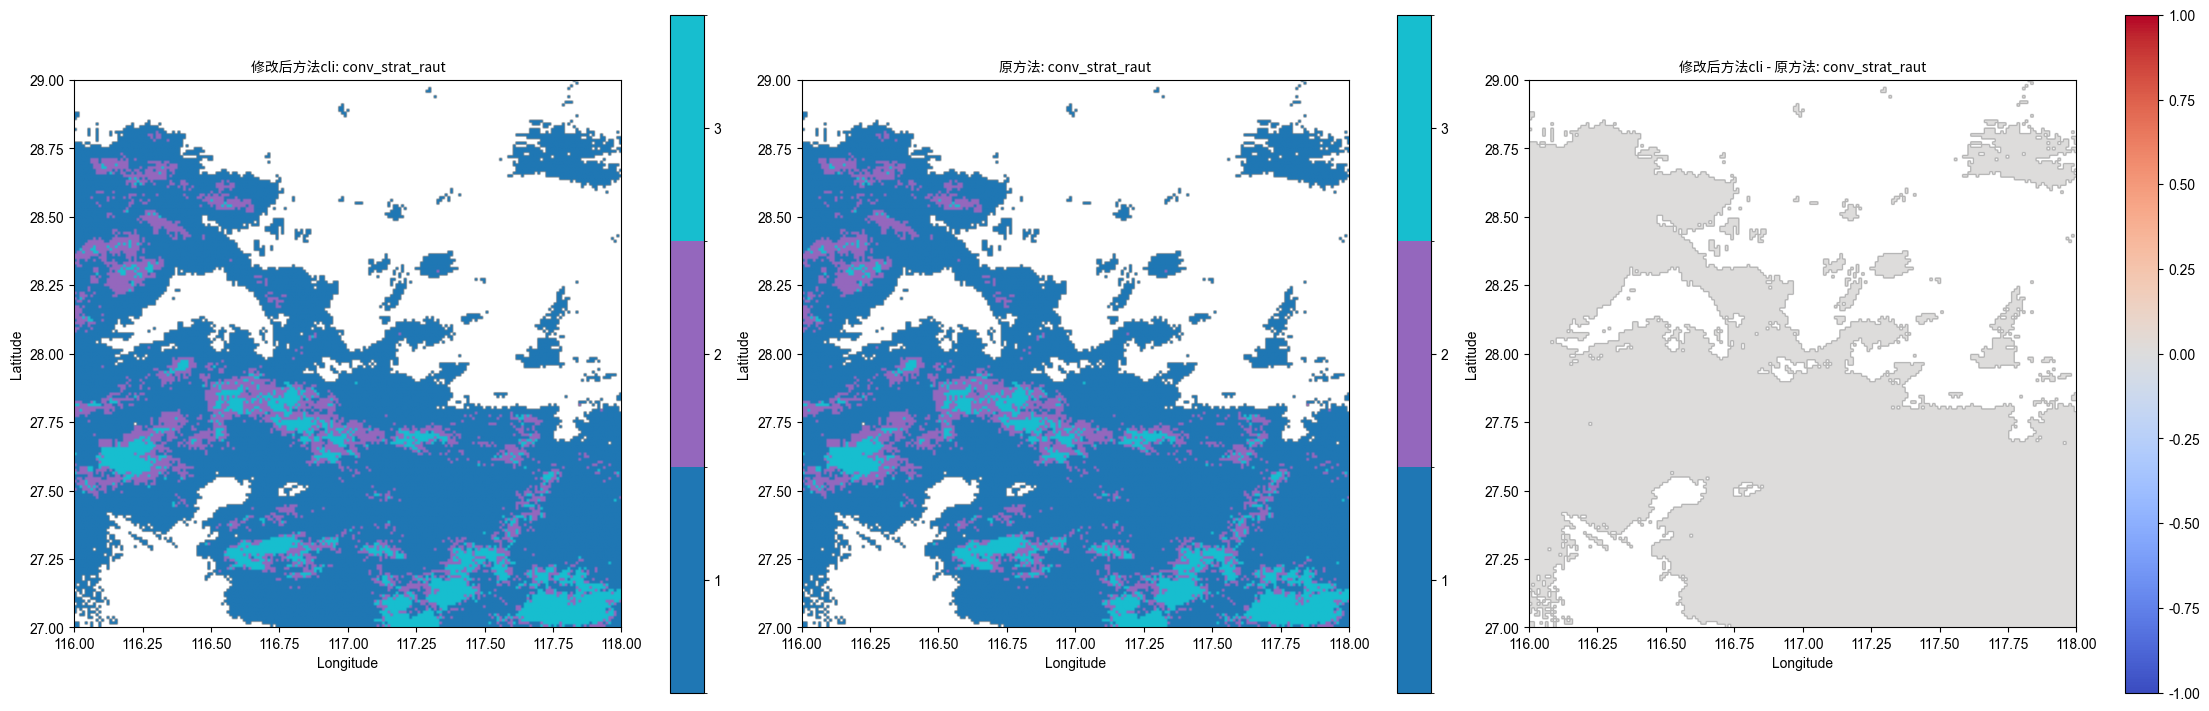

[conv_strat_raut] CLI vs plugin match: 1.0


In [24]:
from radar_echo_classification.cli.conv_strat_raut_main import process as conv_strat_raut

conv_strat_raut(
    str(CLI_INPUT / "ACHN_CREF000_20240612_070000_small.nc"),
    cappi_level=0,
    output_path=str(CLI_OUTPUT / "achn_raut_cli.nc"),
)

# Raut wavelet conv-strat
raut_cli_data = read_cli_data_2d(CLI_OUTPUT / "achn_raut_cli.nc")
plot_categorical_comparison(
    "conv_strat_raut",
    raut_cli_data,
    np.asarray(original_raut_data, dtype=np.float32),
    achn_extent,
    left_title="修改后方法cli: conv_strat_raut",
    right_title="原方法: conv_strat_raut",
    diff_title="修改后方法cli - 原方法: conv_strat_raut",
)
valid = np.isfinite(raut_cli_data) & np.isfinite(np.asarray(migrated_raut_data, dtype=np.float32))
print("[conv_strat_raut] CLI vs plugin match:", float(np.mean((raut_cli_data == np.asarray(migrated_raut_data, dtype=np.float32))[valid].astype(np.float32))))


### 8.4 hydroclass_semisupervised


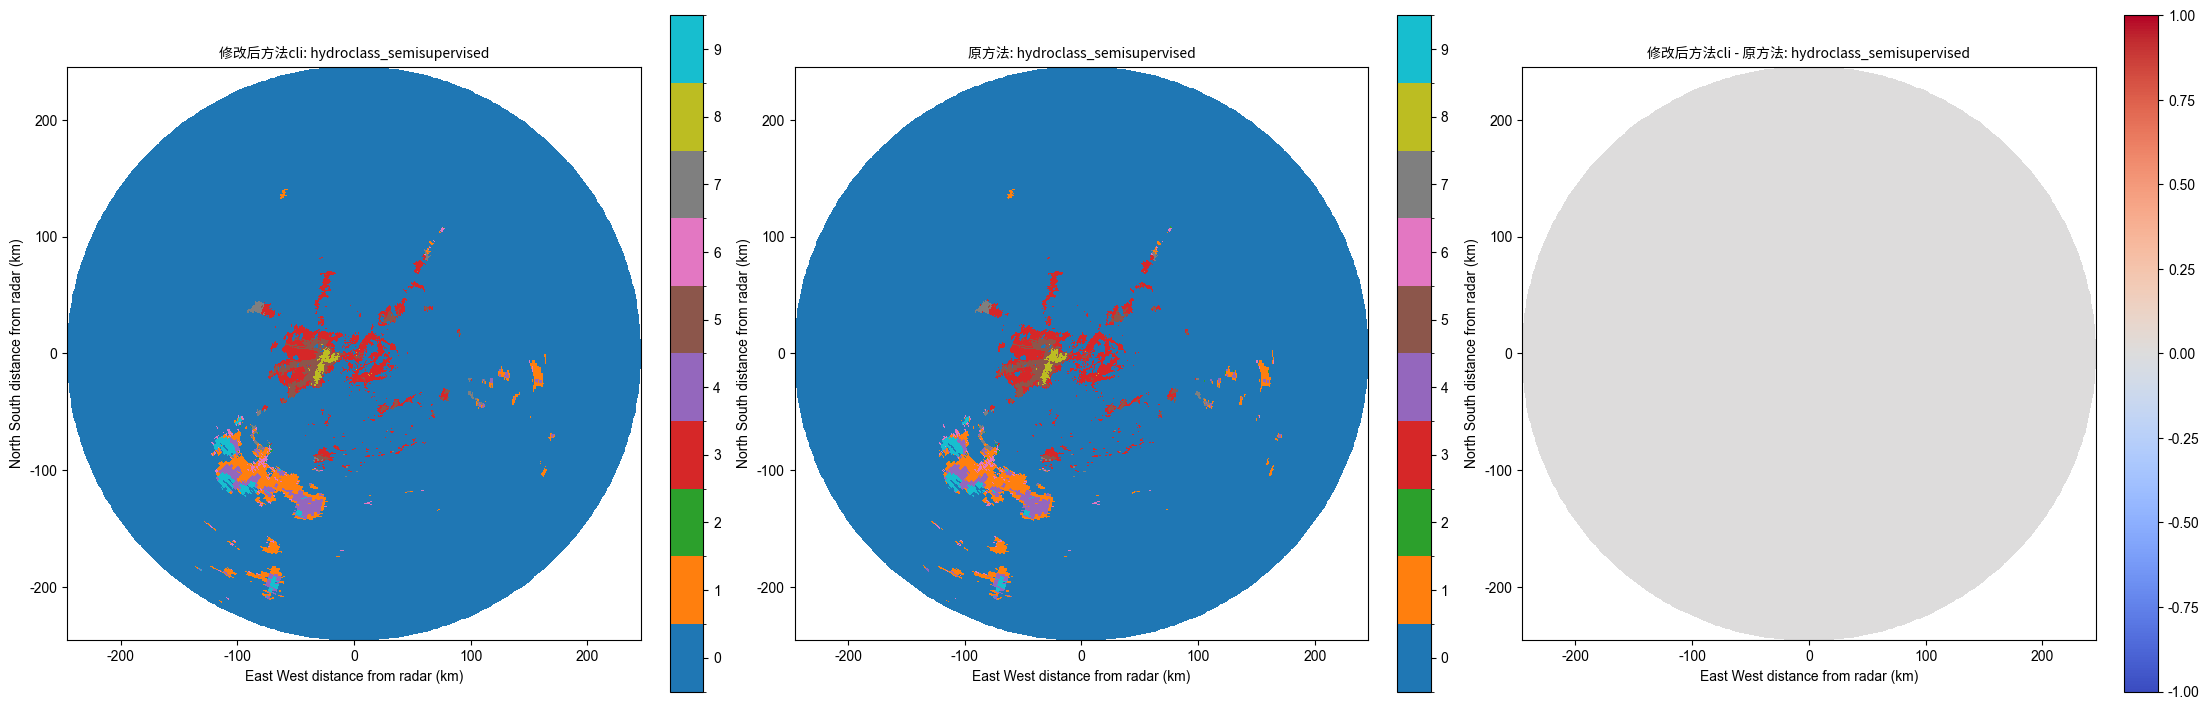

[hydroclass_semisupervised] CLI vs plugin match: 1.0


In [25]:
from radar_echo_classification.cli.hydroclass_semisupervised_main import process as hydroclass_semisupervised

hydroclass_semisupervised(
    refl_path=str(CLI_INPUT / "hydro_corrected_reflectivity.nc"),
    zdr_path=str(CLI_INPUT / "hydro_corrected_differential_reflectivity.nc"),
    kdp_path=str(CLI_INPUT / "hydro_specific_differential_phase.nc"),
    rhv_path=str(CLI_INPUT / "hydro_uncorrected_cross_correlation_ratio.nc"),
    temp_path=str(CLI_INPUT / "hydro_temperature.nc"),
    output_path=str(CLI_OUTPUT / "hydroclass_cli.nc"),
)

# hydroclass_semisupervised
hydro_cli_data = read_cli_data_2d(CLI_OUTPUT / "hydroclass_cli.nc")
hydro_gate_x, hydro_gate_y, _ = hydro_radar.get_gate_x_y_z(hydro_sweep_index)
hydro_gate_x_km = np.asarray(hydro_gate_x, dtype=np.float32) / 1000.0
hydro_gate_y_km = np.asarray(hydro_gate_y, dtype=np.float32) / 1000.0

plot_categorical_comparison(
    "hydroclass_semisupervised",
    hydro_cli_data,
    official_hydro_data,
    x_coords=hydro_gate_x_km,
    y_coords=hydro_gate_y_km,
    x_label="East West distance from radar (km)",
    y_label="North South distance from radar (km)",
    left_title="修改后方法cli: hydroclass_semisupervised",
    right_title="原方法: hydroclass_semisupervised",
    diff_title="修改后方法cli - 原方法: hydroclass_semisupervised",
)
valid = np.isfinite(hydro_cli_data) & np.isfinite(migrated_hydro_data)
print("[hydroclass_semisupervised] CLI vs plugin match:", float(np.mean((hydro_cli_data == migrated_hydro_data)[valid].astype(np.float32))))


## 9. 插件结果展示

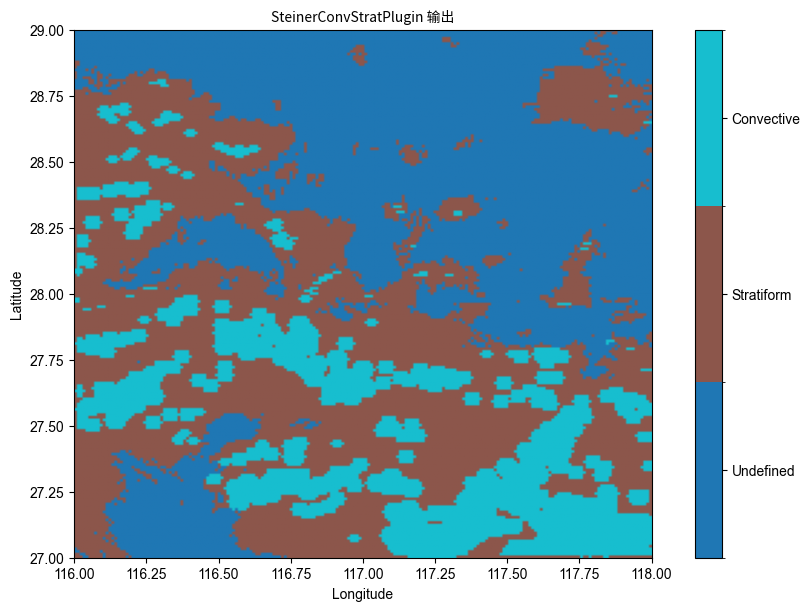

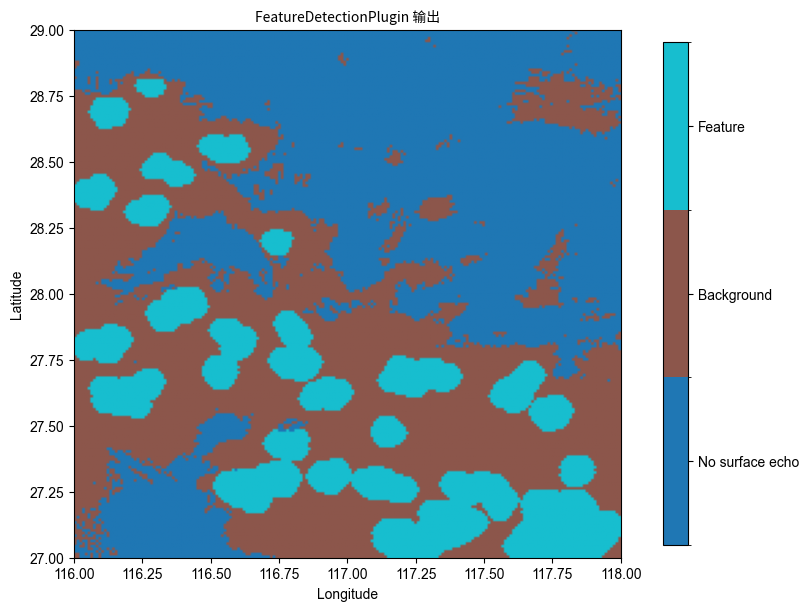

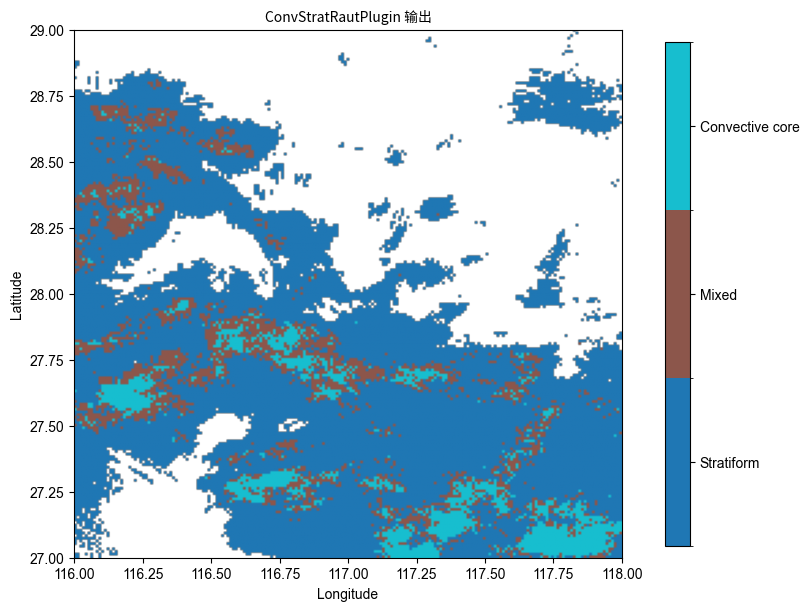

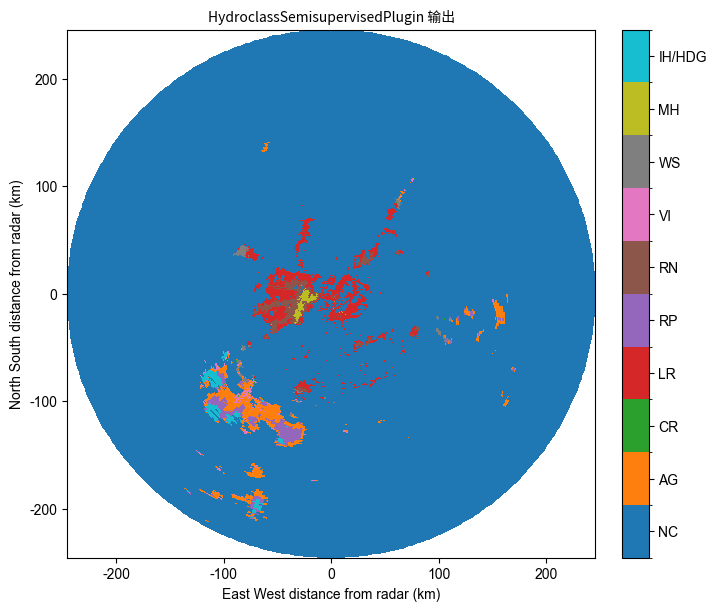

In [26]:
def plot_plugin_output(
    title,
    data,
    class_values,
    class_labels,
    *,
    extent=None,
    x_coords=None,
    y_coords=None,
    x_label="Longitude",
    y_label="Latitude",
):
    # 获取中文字体
    my_font = FontProperties(fname=get_font_path())
    plot_data = np.asarray(data, dtype=np.float32)
    class_ticks = np.asarray(class_values, dtype=np.float32)
    boundaries = np.arange(float(class_ticks.min()) - 0.5, float(class_ticks.max()) + 1.5, 1.0)
    cmap = plt.get_cmap("tab10", len(class_ticks))
    norm = BoundaryNorm(boundaries, cmap.N)

    fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)

    if x_coords is not None and y_coords is not None:
        im = ax.pcolormesh(
            np.asarray(x_coords, dtype=np.float32),
            np.asarray(y_coords, dtype=np.float32),
            plot_data,
            shading="auto",
            cmap=cmap,
            norm=norm,
        )
        ax.set_aspect("equal", "box")
    else:
        im = ax.imshow(
            plot_data,
            origin="lower",
            extent=extent,
            cmap=cmap,
            norm=norm,
            aspect="auto",
        )

    ax.set_title(title, fontproperties=my_font)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_ticks(class_ticks)
    cb.set_ticklabels(class_labels)
    display(fig)
    plt.close(fig)


plugin_output_specs = [
    {
        "title": "SteinerConvStratPlugin 输出",
        "data": migrated_steiner_data,
        "class_values": [0, 1, 2],
        "class_labels": ["Undefined", "Stratiform", "Convective"],
        "extent": achn_extent,
    },
    {
        "title": "FeatureDetectionPlugin 输出",
        "data": migrated_feature_data,
        "class_values": [0, 1, 2],
        "class_labels": ["No surface echo", "Background", "Feature"],
        "extent": achn_extent,
    },
    {
        "title": "ConvStratRautPlugin 输出",
        "data": migrated_raut_data,
        "class_values": [1, 2, 3],
        "class_labels": ["Stratiform", "Mixed", "Convective core"],
        "extent": achn_extent,
    },
    {
        "title": "HydroclassSemisupervisedPlugin 输出",
        "data": migrated_hydro_data,
        "class_values": np.arange(len(hydro_labels), dtype=np.float32),
        "class_labels": hydro_labels,
        "x_coords": hydro_gate_x_km,
        "y_coords": hydro_gate_y_km,
        "x_label": "East West distance from radar (km)",
        "y_label": "North South distance from radar (km)",
    },
]

for spec in plugin_output_specs:
    plot_plugin_output(**spec)